# Actividad Práctica Unidades 1 y 2
## Introducción al aprendizaje automático y fundamentos del análisis de datos

**Dataset:** Heart Disease UCI (Cleveland)  
**Autor:** Ismael Hernández  
**Fecha:** 3 de noviembre de 2026

**Fuente:** Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1988). *Heart Disease*. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X  
**Licencia:** Creative Commons Attribution 4.0 International (CC BY 4.0).  
**Artículo relacionado:** Detrano, R., Jánosi, A., Steinbrunn, W., Pfisterer, M., Schmid, J., Sandhu, S., Guppy, K. H., Lee, S., & Froelicher, V. (1989). International application of a new probability algorithm for the diagnosis of coronary artery disease. *American Journal of Cardiology*, 64(5), 304-310.

Este notebook está pensado para ejecutarse de principio a fin con *Restart & Run All*. Carga el archivo `heart_disease_cleveland.csv` que va en la misma carpeta; si no lo encuentra, intenta leer la URL clásica de UCI. La semilla está fijada en 42.

## 0. Introducción

En esta práctica trabajo con el dataset **Heart Disease** de UCI, en concreto la base de **Cleveland**. El objetivo no es entrenar un modelo, sino dejar un conjunto de datos limpio, explorado y codificado, listo para la práctica de clasificación. He preferido hacer todo el análisis en un único notebook porque así se ve la trazabilidad de cada decisión: qué datos entran, qué errores meto, cómo los detecto y qué queda al final.

He elegido un problema de **clasificación** porque la variable `num` indica presencia o ausencia de enfermedad coronaria. Podría haber planteado una regresión ordinal con los valores 0-4, pero la clase 4 solo tiene 13 casos y la pregunta clínica habitual es binaria: ¿hay enfermedad o no? Binarizar simplifica el problema y evita que un modelo tenga que aprender cinco niveles con muy pocos ejemplos en algunos de ellos. Lo que pierdo es la gravedad: no es lo mismo `num=1` que `num=4`, y eso lo tengo en cuenta al interpretar.

La fuente es el repositorio de UCI. He descargado el archivo `processed.cleveland.data`, que contiene 303 pacientes y 14 columnas, y lo he guardado como CSV con cabecera. El dataset original usa `?` para los valores perdidos; pandas los leerá como nulos si se lo indico. La licencia es CC BY 4.0, así que se puede usar citando la fuente.

Para que el resultado sea reproducible, fijo `np.random.seed(42)` y uso `random_state=42` cuando la función lo permite. Las inyecciones de errores usan un generador local con la misma semilla para que no dependan de otras llamadas aleatorias. El notebook importa solo pandas, numpy, matplotlib y seaborn. Seaborn necesita scipy por dentro para calcular el KDE; no lo importo directamente, pero está instalado en el entorno de ejecución.

Antes de cargar nada, preparo las librerías, el estilo de los gráficos y las constantes que voy a repetir. Así evito colores distintos en cada figura y nombres de columnas escritos a mano en veinte sitios.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 9

PALETA_CLASES = {0: '#4C72B0', 1: '#C44E52'}
ETIQUETAS_CLASES = ['No enfermedad', 'Sí enfermedad']
COLS_NUM = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
COLS_CAT = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

ETIQUETAS_VARS = {
    'age': 'Edad (años)',
    'trestbps': 'Presión arterial (mm Hg)',
    'chol': 'Colesterol (mg/dl)',
    'thalach': 'Frecuencia cardíaca máxima',
    'oldpeak': 'Depresión del segmento ST'
}

ETIQUETAS_CAT = {
    'sex': 'Sexo',
    'cp': 'Tipo de dolor torácico',
    'restecg': 'ECG en reposo',
    'slope': 'Pendiente del segmento ST',
    'ca': 'Vasos afectados',
    'thal': 'Talasemia',
    'fbs': 'Glucemia en ayunas',
    'exang': 'Angina por ejercicio'
}

TICKS_CAT = {
    'sex': ['Mujer', 'Hombre'],
    'cp': ['Típica', 'Atípica', 'No anginoso', 'Asintomático'],
    'restecg': ['Normal', 'Anomalía ST-T', 'Hipertrofia VI'],
    'slope': ['Ascendente', 'Plano', 'Descendente'],
    'ca': ['0', '1', '2', '3'],
    'thal': ['Normal', 'Defecto fijo', 'Defecto reversible'],
    'fbs': ['No', 'Sí'],
    'exang': ['No', 'Sí']
}

print('Librerías cargadas y semilla fijada en 42.')

Librerías cargadas y semilla fijada en 42.


He dejado las constantes en un solo sitio. `COLS_NUM` contiene las cinco variables realmente continuas o discretas con sentido numérico; `COLS_CAT` contiene las que son códigos. Los nombres de las columnas se quedan en inglés para no romper la trazabilidad con UCI; mis variables de código y los comentarios van en español.

## 1. Carga y exploración inicial

### 1.1 Carga del CSV

Voy a cargar el archivo con nombres de columna explícitos y con `na_values='?'`, porque en el fichero original los nulos están codificados como interrogaciones. Si el CSV local no está en la carpeta, hago un intento con la URL clásica de UCI. Prefiero la carga local para que el notebook no dependa de internet; el fallback es solo una red de seguridad.

In [2]:
COLUMNAS = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
            'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
RUTA_LOCAL = 'heart_disease_cleveland.csv'
URL_UCI = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'

try:
    df = pd.read_csv(RUTA_LOCAL, na_values='?')
    print(f'Cargado desde {RUTA_LOCAL}')
except FileNotFoundError:
    df = pd.read_csv(URL_UCI, header=None, names=COLUMNAS, na_values='?')
    print('CSV local no encontrado; cargado desde la URL de UCI')

print(f'Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas')
df.head()

Cargado desde heart_disease_cleveland.csv
Dimensiones: 303 filas x 14 columnas


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


La carga ha funcionado y el DataFrame tiene 303 filas y 14 columnas. En las primeras filas ya se ve el problema: `cp`, `restecg`, `slope`, `ca`, `thal` y `num` son números, pero no son magnitudes; son códigos. `sex`, `fbs` y `exang` son binarias. Las columnas `ca` y `thal` aparecen como `float` porque contienen nulos.

### 1.2 Dimensiones, tipos y primeras comprobaciones

Ahora reviso `info()` y los tipos. Quiero confirmar cuántos valores no nulos hay y si pandas ha interpretado como numéricas variables que en realidad son categóricas. Esto es importante porque un modelo puede sumar, restar o escalar un código sin que tenga sentido.

In [3]:
df.info()
print('\nTipos por columna:')
print(df.dtypes.to_string())

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Tipos por columna:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope     

`num` es `int64`; el resto son `float64`. Que una columna sea `float` no significa que sea continua: `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca` y `thal` son códigos. `ca` tiene 299 valores no nulos y `thal` 301; el resto no tiene nulos. Esa diferencia de tipos es la primera cosa que tendré que corregir antes de codificar.

### 1.3 Estadísticos descriptivos, nulos y duplicados

Miro el `describe()`, el recuento de nulos y los duplicados. En esta fase no limpio nada; solo quiero una foto inicial. El `describe()` de las categóricas codificadas no se interpreta como una media real, pero sirve para ver rangos y detectar valores raros.

In [4]:
print('Nulos por columna:')
print(df.isna().sum().to_string())
print(f'\nCeldas nulas: {int(df.isna().sum().sum())} de {df.shape[0] * df.shape[1]}')
print(f'Filas duplicadas: {int(df.duplicated().sum())}')

df.describe().T.round(2)

Nulos por columna:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0

Celdas nulas: 6 de 4242
Filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


Hay **6 celdas nulas** repartidas en 6 filas: 4 en `ca` y 2 en `thal`. Eso es el 1,98% de las filas y el 0,14% de las celdas. No hay duplicados. El resto de columnas están completas. En el `describe()` me llaman la atención `chol` (media 246,69, desviación 51,78, máximo 564) y `oldpeak` (media 1,04, máximo 6,2, mínimo 0). La media de `restecg` (0,99) no significa nada útil porque es un código nominal; es justo el tipo de variable que hay que codificar y no promediar.

### 1.4 Descripción de las variables

| Variable | Significado oficial | Tipo real |
|---|---|---|
| `age` | Edad en años | Numérica continua (discreta en la práctica) |
| `sex` | Sexo (1 = hombre, 0 = mujer) | Categórica binaria nominal |
| `cp` | Tipo de dolor torácico (1 = angina típica, 2 = angina atípica, 3 = dolor no anginoso, 4 = asintomático) | Categórica nominal |
| `trestbps` | Presión arterial en reposo (mm Hg) | Numérica continua |
| `chol` | Colesterol sérico (mg/dl) | Numérica continua |
| `fbs` | Glucemia en ayunas > 120 mg/dl (1 = sí, 0 = no) | Categórica binaria |
| `restecg` | Electrocardiograma en reposo (0 = normal, 1 = anomalía ST-T, 2 = hipertrofia ventricular izquierda) | Categórica nominal |
| `thalach` | Frecuencia cardíaca máxima alcanzada | Numérica continua/discreta |
| `exang` | Angina inducida por ejercicio (1 = sí, 0 = no) | Categórica binaria |
| `oldpeak` | Depresión del segmento ST inducida por ejercicio respecto al reposo | Numérica continua |
| `slope` | Pendiente del segmento ST en el pico del ejercicio (1 = ascendente, 2 = plano, 3 = descendente) | Categórica ordinal |
| `ca` | Número de vasos principales coloreados por fluoroscopia (0-3) | Numérica discreta ordinal |
| `thal` | Talasemia (3 = normal, 6 = defecto fijo, 7 = defecto reversible) | Categórica nominal |
| `num` | Diagnóstico de enfermedad coronaria (0 = <50% de estenosis; 1-4 = >50%) | Objetivo ordinal; lo binarizo |

La variable objetivo original es `num`, con cinco valores. La voy a convertir en `enfermedad`, que vale 1 si `num` es 1, 2, 3 o 4, y 0 si `num` es 0. No uso `num` como predictor después de crear la target, porque sería una fuga de información.

### 1.5 Primera impresión

El dataset es pequeño: 303 pacientes y 13 predictores. La distribución de `num` es 164 casos con 0, 55 con 1, 36 con 2, 35 con 3 y 13 con 4. Al binarizar quedan **164 sin enfermedad (54,1%)** y **139 con enfermedad (45,9%)**, así que no hay un desbalance fuerte. Eso hace que la accuracy no sea una métrica absurda, pero en un contexto clínico no me quedaría solo con ella: un falso negativo pesa más que un falso positivo.

Hay varios detalles que me hacen desconfiar o que quiero vigilar:

- `restecg=1` solo tiene **4 casos** (1,3%). Cualquier tasa calculada con esa categoría va a ser inestable.
- `cp=4` (asintomático) tiene **144 casos** y, como veremos, una tasa de enfermedad alta. A primera vista parece contraintuitivo, pero en una base de pacientes derivados a angiografía puede tener sentido: son personas sin dolor típico que llegan por otros motivos.
- `sex` está desequilibrado: 206 hombres (68,0%) frente a 97 mujeres (32,0%). Es un posible sesgo de selección, no una propiedad de la población general.
- `chol` tiene un máximo de 564 y una cola derecha clara; `oldpeak` tiene muchos ceros y un máximo de 6,2.
- `ca` y `thal` son las únicas columnas con nulos originales, pero son dos de las que más relación parecen tener con la enfermedad. Imputarlas sin cuidado puede mover mucho las conclusiones.

En resumen: hay suciedad original, pero poca. La parte interesante va a ser inyectar errores conocidos y comprobar que soy capaz de detectarlos y corregirlos sin mirar el registro.

## 2. Limpieza y preprocesamiento

### 2.1 Suciedad original

Antes de inyectar nada, mido la suciedad que ya trae el dataset con los mismos criterios que usaré después: nulos, duplicados, categorías fuera de dominio y valores fuera de rangos clínicos. Los rangos son amplios a propósito; no quiero marcar como error un colesterol alto real.

In [5]:
DOMINIOS = {
    'cp': {1, 2, 3, 4},
    'restecg': {0, 1, 2},
    'slope': {1, 2, 3},
    'ca': {0, 1, 2, 3},
    'thal': {3, 6, 7}
}

RANGOS = {
    'age': (18, 100),
    'trestbps': (50, 250),
    'chol': (80, 600),
    'thalach': (60, 220),
    'oldpeak': (0, 10)
}

filas_suciedad = []

for col in df.columns:
    n = int(df[col].isna().sum())
    if n:
        filas_suciedad.append({'problema': 'nulos', 'columna': col, 'n': n})

filas_suciedad.append({'problema': 'duplicados', 'columna': 'fila completa', 'n': int(df.duplicated().sum())})

for col, dominio in DOMINIOS.items():
    n = int((df[col].notna() & ~df[col].isin(dominio)).sum())
    if n:
        filas_suciedad.append({'problema': 'categorías fuera de dominio', 'columna': col, 'n': n})

for col, (lo, hi) in RANGOS.items():
    n = int((df[col].notna() & ((df[col] < lo) | (df[col] > hi))).sum())
    if n:
        filas_suciedad.append({'problema': 'valores fuera de rango', 'columna': col, 'n': n})

pd.DataFrame(filas_suciedad)

,problema,columna,n
0,nulos,ca,4
1,nulos,thal,2
2,duplicados,fila completa,0


La suciedad original es poca: 6 nulos, 0 duplicados, ninguna categoría fuera de dominio y ningún valor fuera de los rangos clínicos que he definido. Eso no significa que el dataset sea perfecto; significa que los errores van a ser los que yo meta. Los rangos son deliberadamente anchos: por ejemplo, acepto colesterol hasta 600 porque un valor de 564 es raro pero posible. Si hubiera usado un rango estrecho habría marcado como error a pacientes reales.

### 2.2 Inyección controlada de errores

Voy a trabajar sobre una copia y a meter errores de varios tipos con un generador local de semilla 42. La gracia es que sé dónde los meto, así que después puedo comprobar si mi detección los encuentra sin usar esa información. Añado una columna `id_paciente` para poder auditar cada fila; no es un predictor y la quitaré al final.

Como el dataset original no tiene columnas de texto, convierto `sex` a `Male`/`Female` en la copia sucia. Esa conversión no es un error: es una simulación de una exportación clínica con etiquetas de texto. Los errores son las variantes mal escritas que meto después (`Male `, `MALE`, `mále`...). Así puedo practicar la normalización de texto sin inventar una columna que no existe.

In [6]:
rng = np.random.default_rng(42)

df_sucio = df.copy()
df_sucio.insert(0, 'id_paciente', df_sucio.index)
df_sucio['sex'] = df_sucio['sex'].map({1.0: 'Male', 0.0: 'Female'})

registro = []
modificados = set()


def filas_disponibles(datos, columna, n, generador, solo_no_nulos=True):
    if solo_no_nulos:
        candidatos = list(datos.index[datos[columna].notna()])
    else:
        candidatos = list(datos.index)
    candidatos = [i for i in candidatos if (i, columna) not in modificados]
    if len(candidatos) < n:
        raise ValueError(f'No hay suficientes filas para {columna}: {len(candidatos)} < {n}')
    return list(generador.choice(candidatos, size=n, replace=False))


def registrar(tipo, columna, fila, valor_original, valor_nuevo, motivo):
    registro.append({
        'tipo_error': tipo,
        'columna': columna,
        'fila': int(fila),
        'valor_original': str(valor_original),
        'valor_nuevo': str(valor_nuevo),
        'motivo': motivo
    })
    modificados.add((fila, columna))


print('Copia sucia creada con', df_sucio.shape[0], 'filas y', df_sucio.shape[1], 'columnas.')

Copia sucia creada con 303 filas y 15 columnas.


La copia tiene 303 filas y 15 columnas (las 14 originales más `id_paciente`). Todavía no he metido ningún error. Las funciones `filas_disponibles` y `registrar` evitan que modifique dos veces la misma celda y guardan el valor antiguo y el nuevo. Eso me permitirá auditar la imputación al final.

Ahora meto los errores. Uso porcentajes pequeños: 9 nulos por columna numérica o categórica (aproximadamente el 3% de las filas), 2 categorías inválidas por columna, 2 outliers plausibles por columna y 8 duplicados. Los valores imposibles son pocos pero muy visibles. Los duplicados van al final para que sean copias exactas de filas que ya están sucias.

In [7]:
# 1) NaNs artificiales en columnas numéricas y categóricas
for col, n in [('trestbps', 9), ('chol', 9), ('cp', 9), ('thal', 9), ('ca', 9)]:
    for fila in filas_disponibles(df_sucio, col, n, rng):
        registrar('nulo artificial', col, fila, df_sucio.at[fila, col], np.nan, 'nulo introducido al azar')
        df_sucio.at[fila, col] = np.nan

# 2) Texto mal codificado, conservando el sexo original
for variante, etiqueta in [('Male ', 'Male'), ('MALE', 'Male'), ('mále', 'Male'), ('MALE ', 'Male'),
                           ('Female ', 'Female'), ('FEMALE', 'Female'), ('fémale', 'Female')]:
    candidatos = [i for i in df_sucio.index[df_sucio['sex'] == etiqueta] if (i, 'sex') not in modificados]
    fila = int(rng.choice(candidatos))
    registrar('texto mal codificado', 'sex', fila, df_sucio.at[fila, 'sex'], variante,
              'espacios, mayúsculas o acentos')
    df_sucio.at[fila, 'sex'] = variante

# 3) Categorías inválidas en sex (además del texto mal formado)
for valor in ['3', 'Unknown']:
    fila = filas_disponibles(df_sucio, 'sex', 1, rng)[0]
    registrar('categoría inválida', 'sex', fila, df_sucio.at[fila, 'sex'], valor, 'valor fuera del dominio')
    df_sucio.at[fila, 'sex'] = valor

# 4) Edades, presiones, colesteroles y frecuencias imposibles
imposibles = [('age', [-5, 0, 250]),
              ('trestbps', [0, -20, 1300]),
              ('chol', [0, -50, 2500]),
              ('thalach', [0, 400]),
              ('oldpeak', [-1.0, 15.0])]
for col, valores in imposibles:
    for valor in valores:
        fila = filas_disponibles(df_sucio, col, 1, rng)[0]
        registrar('valor imposible', col, fila, df_sucio.at[fila, col], valor, 'fuera de rango fisiológico')
        df_sucio.at[fila, col] = valor

# 5) Categorías inexistentes en el resto de columnas
invalidos = [('cp', 9), ('restecg', 5), ('slope', 4), ('ca', 7), ('thal', 99)]
for col, valor in invalidos:
    for fila in filas_disponibles(df_sucio, col, 2, rng):
        registrar('categoría inválida', col, fila, df_sucio.at[fila, col], valor, 'código inexistente')
        df_sucio.at[fila, col] = valor

# 6) Outliers extremos pero clínicamente plausibles
outliers = [('chol', 550.0), ('trestbps', 210.0), ('thalach', 65.0), ('oldpeak', 7.0)]
for col, valor in outliers:
    for fila in filas_disponibles(df_sucio, col, 2, rng):
        registrar('outlier extremo', col, fila, df_sucio.at[fila, col], valor,
                  'valor extremo pero plausible')
        df_sucio.at[fila, col] = valor

# 7) Duplicados exactos, al final, para que copien filas ya sucias
filas_duplicadas = list(rng.choice(df_sucio.index, size=8, replace=False))
for fila in filas_duplicadas:
    registrar('duplicado', 'fila completa', fila, f'fila {fila}', 'copia duplicada', 'duplicado exacto')
df_sucio = pd.concat([df_sucio, df_sucio.loc[filas_duplicadas]], ignore_index=False)

print(f'Dataset sucio: {df_sucio.shape[0]} filas x {df_sucio.shape[1]} columnas')
print(f'Cambios registrados: {len(registro)}')

Dataset sucio: 311 filas x 15 columnas
Cambios registrados: 93


He metido **93 cambios registrados**: 45 nulos artificiales, 13 valores imposibles, 12 categorías inválidas, 7 textos mal codificados, 8 outliers y 8 duplicados. En total es un 2,2% de las celdas del dataset original, más las 8 filas duplicadas. El dataset sucio tiene 311 filas.

Cada error tiene un impacto distinto en un modelo:

- **Nulos artificiales**: muchos modelos no aceptan nulos; si se imputan con la media, la media se sesga; si se eliminan filas, se pierde información.
- **Edades negativas o de 250, presiones de 1300 o colesteroles de 2500**: rompen la escala, disparan la media y la desviación, y en un modelo lineal o en k-NN pueden dominar la distancia.
- **Categorías inválidas (`cp=9`, `thal=99`)**: un one-hot crea una columna para una categoría que no existe; si el encoder se ajusta en train y aparece otra categoría en test, el modelo falla o la ignora.
- **Textos mal codificados (`Male `, `MALE`, `mále`)**: el mismo sexo se convierte en tres categorías distintas; el one-hot pierde señal y el modelo aprende de diferencias que son solo formato.
- **Duplicados**: si una copia cae en train y otra en test, el modelo se evalúa con información que ya ha visto; las métricas salen infladas y la mediana se sesga.
- **Outliers plausibles**: no son errores imposibles, pero inflan la varianza y pueden arrastrar la media y los coeficientes. En un contexto clínico no siempre se deben borrar: un colesterol de 550 puede ser real.

### 2.3 Registro de errores

Guardo el resumen por tipo y columna y enseño las primeras filas del detalle. El registro no lo voy a usar para detectar; lo usaré al final para comprobar que no se me ha escapado nada.

In [8]:
registro_df = pd.DataFrame(registro)

print(f'Cambios registrados: {len(registro_df)}')
print(f'Celdas del dataset original: {df.shape[0] * df.shape[1]}')
print(f'Porcentaje de celdas modificadas: {len(registro_df) / (df.shape[0] * df.shape[1]) * 100:.2f}%')

resumen_registro = (registro_df.groupby(['tipo_error', 'columna'])
                    .size()
                    .reset_index(name='n')
                    .sort_values(['tipo_error', 'columna']))

print('\nDetalle (primeras 10 filas):')
print(registro_df.head(10).to_string(index=False))

print('\nResumen por tipo de error y columna:')
resumen_registro

Cambios registrados: 93
Celdas del dataset original: 4242
Porcentaje de celdas modificadas: 2.19%

Detalle (primeras 10 filas):
     tipo_error  columna  fila valor_original valor_nuevo                   motivo
nulo artificial trestbps    61          142.0         nan nulo introducido al azar
nulo artificial trestbps   229          112.0         nan nulo introducido al azar
nulo artificial trestbps   257          140.0         nan nulo introducido al azar
nulo artificial trestbps   194          120.0         nan nulo introducido al azar
nulo artificial trestbps   130          120.0         nan nulo introducido al azar
nulo artificial trestbps   210          120.0         nan nulo introducido al azar
nulo artificial trestbps    25          120.0         nan nulo introducido al azar
nulo artificial trestbps   129          124.0         nan nulo introducido al azar
nulo artificial trestbps    26          120.0         nan nulo introducido al azar
nulo artificial     chol   110          30

,tipo_error,columna,n
0,categoría inválida,ca,2
1,categoría inválida,cp,2
2,categoría inválida,restecg,2
3,categoría inválida,sex,2
4,categoría inválida,slope,2
5,categoría inválida,thal,2
6,duplicado,fila completa,8
7,nulo artificial,ca,9
8,nulo artificial,chol,9
9,nulo artificial,cp,9


El resumen cuadra con lo que quería: los nulos están repartidos entre `trestbps`, `chol`, `cp`, `thal` y `ca`; las categorías inválidas están en `sex`, `cp`, `restecg`, `slope`, `ca` y `thal`; los valores imposibles están en las cinco numéricas; y los duplicados afectan a la fila completa. El detalle guarda la fila, el valor original y el nuevo, así que puedo auditar la imputación sin volver a mirar el dataset sucio.

### 2.4 Detección automática sin mirar el registro

Empiezo por los duplicados. Después trabajo con las filas únicas para no contar dos veces el mismo error: si una fila con un nulo se duplica, el nulo aparece dos veces y el recuento se infla. Primero detecto y elimino las copias; luego busco nulos, dominios, rangos y texto.

In [9]:
duplicados_eliminar = int(df_sucio.duplicated(keep='first').sum())
duplicados_implicados = int(df_sucio.duplicated(keep=False).sum())

print(f'Duplicados exactos a eliminar: {duplicados_eliminar}')
print(f'Filas implicadas (original + copia): {duplicados_implicados}')
print('\nEjemplos de filas duplicadas:')
print(df_sucio.loc[df_sucio.duplicated(keep=False), ['id_paciente', 'age', 'sex', 'chol']]
      .sort_values('id_paciente').head(10).to_string(index=False))

df_det = df_sucio.drop_duplicates(keep='first').reset_index(drop=True)
print(f'\nFilas únicas para seguir detectando: {df_det.shape[0]}')

Duplicados exactos a eliminar: 8
Filas implicadas (original + copia): 16

Ejemplos de filas duplicadas:
 id_paciente  age  sex  chol
           9 53.0 Male 203.0
           9 53.0 Male 203.0
          65 60.0 Male 282.0
          65 60.0 Male 282.0
          90 66.0 Male 302.0
          90 66.0 Male 302.0
         104 49.0 Male 188.0
         104 49.0 Male 188.0
         131 51.0 Male 227.0
         131 51.0 Male 227.0

Filas únicas para seguir detectando: 303


Hay 8 duplicados que implican 16 filas: cada copia y su original. Al eliminar las copias vuelvo a 303 filas. A partir de aquí trabajo con `df_det`, que tiene las filas únicas pero sigue sucia.

Ahora detecto nulos, categorías fuera de dominio, valores fuera de rango y textos no canónicos. Para `sex` normalizo espacios, mayúsculas y acentos y comparo con `Male`/`Female`. Para las categóricas numéricas uso los dominios que definí antes. Para las numéricas uso los rangos clínicos. Todo esto sale de los datos; no consulto `registro_df`.

In [10]:
sexo_normalizado = (df_det['sex'].astype(str).str.strip().str.lower()
                    .str.replace('á', 'a', regex=False)
                    .str.replace('é', 'e', regex=False)
                    .str.replace('í', 'i', regex=False)
                    .str.replace('ó', 'o', regex=False)
                    .str.replace('ú', 'u', regex=False)
                    .str.replace('ü', 'u', regex=False))

sexo_canonico = df_det['sex'].isin(['Male', 'Female'])
texto_mal = (~sexo_canonico) & sexo_normalizado.isin(['male', 'female'])
sexo_invalido = (~sexo_canonico) & (~sexo_normalizado.isin(['male', 'female']))

informe = []


def anadir(problema, columna, mascara, detalle=''):
    n = int(mascara.sum())
    if n:
        informe.append({'problema': problema, 'columna': columna, 'n': n, 'detalle': detalle})


for col in df_det.columns:
    anadir('nulo', col, df_det[col].isna())

for col, dominio in DOMINIOS.items():
    anadir('categoría fuera de dominio', col, df_det[col].notna() & ~df_det[col].isin(dominio))

for col, (lo, hi) in RANGOS.items():
    anadir('valor fuera de rango', col, df_det[col].notna() & ((df_det[col] < lo) | (df_det[col] > hi)))

anadir('texto mal codificado', 'sex', texto_mal)
anadir('sexo inválido', 'sex', sexo_invalido)

informe_df = pd.DataFrame(informe)
informe_df

,problema,columna,n,detalle
0,nulo,cp,9,
1,nulo,trestbps,9,
2,nulo,chol,9,
3,nulo,ca,13,
4,nulo,thal,11,
5,categoría fuera de dominio,cp,2,
6,categoría fuera de dominio,restecg,2,
7,categoría fuera de dominio,slope,2,
8,categoría fuera de dominio,ca,2,
9,categoría fuera de dominio,thal,2,


La detección encuentra **51 nulos** (6 originales + 45 inyectados), **2 sexos inválidos**, **7 textos mal codificados**, **2 categorías fuera de dominio en cada una de `cp`, `restecg`, `slope`, `ca` y `thal`**, y los valores imposibles: 3 en `age`, 3 en `trestbps`, 3 en `chol`, 2 en `thalach` y 2 en `oldpeak`. Los conteos coinciden con el registro, pero no he mirado el registro para encontrarlos.

En los nulos se ve el efecto de los originales: `ca` tiene 13 (4 originales + 9 inyectados) y `thal` 11 (2 + 9). `cp`, `trestbps` y `chol` tienen 9 cada uno, todos inyectados.

Enseño algunos ejemplos para que no quede solo en números. Quiero ver que las máscaras apuntan a valores concretos y no a filas al azar.

In [11]:
print('Edades imposibles:')
print(df_det.loc[df_det['age'].notna() & ~df_det['age'].between(18, 100), ['id_paciente', 'age']]
      .to_string(index=False))

print('\nTextos de sexo no canónicos:')
print(df_det.loc[~df_det['sex'].isin(['Male', 'Female']), ['id_paciente', 'sex']]
      .to_string(index=False))

print('\nCategorías inválidas en cp:')
print(df_det.loc[df_det['cp'].notna() & ~df_det['cp'].isin(DOMINIOS['cp']), ['id_paciente', 'cp']]
      .to_string(index=False))

print('\noldpeak imposible:')
print(df_det.loc[df_det['oldpeak'].notna() & ~df_det['oldpeak'].between(0, 10), ['id_paciente', 'oldpeak']]
      .to_string(index=False))

Edades imposibles:
 id_paciente   age
          72 250.0
          87   0.0
         272  -5.0

Textos de sexo no canónicos:
 id_paciente     sex
          28    MALE
          86    mále
         116 Unknown
         149  FEMALE
         204   Male 
         232   MALE 
         241  fémale
         253 Female 
         256       3

Categorías inválidas en cp:
 id_paciente  cp
         141 9.0
         198 9.0

oldpeak imposible:
 id_paciente  oldpeak
         235     15.0
         238     -1.0


Los ejemplos confirman lo que buscaba: edades de -5, 0 y 250, un `sex` con `3` y `Unknown`, un `cp=9` y un `oldpeak=15`. No están todos en la misma fila ni en la misma columna, así que una inspección manual habría sido lenta y fácil de dejar incompleta.

Ahora los outliers. Uso dos criterios: el rango intercuartílico (IQR) con factores 1,5 y 3, y el z-score con umbral 3. Los conteos todavía incluyen los valores imposibles, así que están inflados; más adelante, cuando los pase a nulo, repetiré el cálculo para decidir el recorte.

In [12]:
def limites_iqr(serie, k=1.5):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


filas_outliers = []

for col in COLS_NUM:
    serie = df_det[col].dropna()
    for k in [1.5, 3.0]:
        lo, hi = limites_iqr(serie, k)
        n = int(((serie < lo) | (serie > hi)).sum())
        filas_outliers.append({
            'columna': col,
            'criterio': f'IQR x{k}',
            'n': n,
            'limite_inferior': round(lo, 2),
            'limite_superior': round(hi, 2)
        })
    z = (serie - serie.mean()) / serie.std()
    filas_outliers.append({
        'columna': col,
        'criterio': 'z-score > 3',
        'n': int((z.abs() > 3).sum()),
        'limite_inferior': None,
        'limite_superior': None
    })

pd.DataFrame(filas_outliers)

,columna,criterio,n,limite_inferior,limite_superior
0,age,IQR x1.5,3,27.25,81.25
1,age,IQR x3.0,3,7.00,101.50
2,age,z-score > 3,3,NaN,NaN
3,trestbps,IQR x1.5,14,90.00,170.00
4,trestbps,IQR x3.0,5,60.00,200.00
5,trestbps,z-score > 3,1,NaN,NaN
6,chol,IQR x1.5,10,113.50,371.50
7,chol,IQR x3.0,6,16.75,468.25
8,chol,z-score > 3,1,NaN,NaN
9,thalach,IQR x1.5,5,82.25,216.25


El IQR y el z-score no coinciden, y eso es informativo. El z-score se dispara con los valores imposibles y con la cola de `oldpeak`: marca 5 outliers en `oldpeak` y 3 en `age`, que son precisamente los valores que he metido. El IQR con 1,5 es más estable, pero también marca valores reales. Por eso no voy a usar el z-score para decidir el recorte: lo dejo como diagnóstico y uso el IQR, que es menos sensible a unas pocas observaciones extremas.

En `age`, los 3 outliers son -5, 0 y 250; en `chol`, los 10 de 1,5×IQR incluyen 0, -50 y 2500. Cuando esos valores pasen a nulo, el recuento bajará. Esa comparación es la que me interesa para elegir entre 1,5×IQR y 3×IQR.

### 2.5 Limpieza paso a paso

Empiezo con `df_det`, que ya no tiene duplicados. Primero normalizo `sex`, luego paso los valores imposibles y las categorías inválidas a nulo. No imputo todavía: quiero ver cuántos nulos quedan y de qué tipo antes de decidir la mediana o la moda.

In [13]:
df_limpio = df_det.copy()

sexo_normalizado = (df_limpio['sex'].astype(str).str.strip().str.lower()
                    .str.replace('á', 'a', regex=False)
                    .str.replace('é', 'e', regex=False)
                    .str.replace('í', 'i', regex=False)
                    .str.replace('ó', 'o', regex=False)
                    .str.replace('ú', 'u', regex=False)
                    .str.replace('ü', 'u', regex=False))

df_limpio['sex'] = sexo_normalizado.map({'female': 0, 'male': 1})

print('Sexo después de normalizar:', sorted(df_limpio['sex'].dropna().unique().tolist()))
print('Sexo nulo tras normalizar:', int(df_limpio['sex'].isna().sum()))

print('\nValores imposibles pasados a nulo:')
for col, (lo, hi) in RANGOS.items():
    mascara = df_limpio[col].notna() & ~df_limpio[col].between(lo, hi)
    print(f'  {col}: {int(mascara.sum())}')
    df_limpio.loc[mascara, col] = np.nan

print('\nCategorías fuera de dominio pasadas a nulo:')
for col, dominio in DOMINIOS.items():
    mascara = df_limpio[col].notna() & ~df_limpio[col].isin(dominio)
    print(f'  {col}: {int(mascara.sum())}')
    df_limpio.loc[mascara, col] = np.nan

Sexo después de normalizar: [0.0, 1.0]
Sexo nulo tras normalizar: 2

Valores imposibles pasados a nulo:
  age: 3
  trestbps: 3
  chol: 3
  thalach: 2
  oldpeak: 2

Categorías fuera de dominio pasadas a nulo:
  cp: 2
  restecg: 2
  slope: 2


  ca: 2
  thal: 2


He pasado a nulo **13 valores imposibles** (3 de edad, 3 de presión, 3 de colesterol, 2 de frecuencia cardíaca y 2 de `oldpeak`) y **10 categorías fuera de dominio** (2 en cada una de las cinco columnas). En `sex` había 2 valores inválidos que la normalización convirtió en nulo. No queda ningún valor imposible, pero ahora hay más nulos que antes: esos son los que voy a imputar.

Para imputar uso la mediana en numéricas y la moda en categóricas. La mediana es más robusta que la media cuando hay asimetría y valores extremos, que es el caso de `chol` y `oldpeak`. La moda es la opción más simple para categóricas, pero tiene un sesgo claro: refuerza la categoría mayoritaria. Lo asumo y lo mediré en la auditoría.

In [14]:
medianas = df_limpio[COLS_NUM].median()
modas = df_limpio[COLS_CAT].mode().iloc[0]

print('Medianas usadas:')
print(medianas.round(2).to_string())
print('\nModas usadas:')
print(modas.to_string())

df_limpio[COLS_NUM] = df_limpio[COLS_NUM].fillna(medianas)
df_limpio[COLS_CAT] = df_limpio[COLS_CAT].fillna(modas)
df_limpio[COLS_CAT] = df_limpio[COLS_CAT].astype(int)

print('\nNulos después de imputar:', int(df_limpio.isna().sum().sum()))

Medianas usadas:


age          56.0
trestbps    130.0
chol        240.0
thalach     152.0
oldpeak       0.8

Modas usadas:
sex        1.0
cp         4.0
fbs        0.0
restecg    0.0
exang      0.0
slope      1.0
ca         0.0
thal       3.0

Nulos después de imputar: 0


Las medianas son 56 años, 130 mm Hg, 240 mg/dl, 152 lpm y 0,8 de `oldpeak`. Las modas son `sex=1`, `cp=4`, `fbs=0`, `restecg=0`, `exang=0`, `slope=1`, `ca=0` y `thal=3`. No hay nulos después de imputar. La moda de `cp=4` y la de `thal=3` son las que más me preocupan, porque son categorías mayoritarias y pueden tapar casos minoritarios.

Ahora los outliers. Comparo 1,5×IQR y 3×IQR después de imputar, para que los valores imposibles ya no contaminen los cuartiles. Decido recortar solo con 3×IQR: quiero limitar los extremos sin borrar pacientes ni cambiar valores que podrían ser reales. En `thalach` el criterio no recorta nada y mantengo el 65.

In [15]:
print('Comparación de recorte de outliers (después de imputar):')
for col in ['chol', 'trestbps', 'oldpeak', 'thalach']:
    lo15, hi15 = limites_iqr(df_limpio[col], 1.5)
    lo3, hi3 = limites_iqr(df_limpio[col], 3.0)
    n15 = int(((df_limpio[col] < lo15) | (df_limpio[col] > hi15)).sum())
    n3 = int(((df_limpio[col] < lo3) | (df_limpio[col] > hi3)).sum())
    print(f'{col}: 1,5×IQR recortaría {n15}; 3×IQR recortaría {n3} '
          f'(límites {lo3:.2f}, {hi3:.2f})')
    df_limpio[col] = df_limpio[col].clip(lo3, hi3)

df_limpio['enfermedad'] = (df_limpio['num'] > 0).astype(int)

print('\nMínimos y máximos después del recorte:')
print(df_limpio[COLS_NUM].agg(['min', 'max']).T.round(2).to_string())
print('\nDistribución de la target:')
print(df_limpio['enfermedad'].value_counts().sort_index().to_string())

Comparación de recorte de outliers (después de imputar):


chol: 1,5×IQR recortaría 7; 3×IQR recortaría 3 (límites 25.50, 459.50)
trestbps: 1,5×IQR recortaría 11; 3×IQR recortaría 2 (límites 60.00, 200.00)
oldpeak: 1,5×IQR recortaría 7; 3×IQR recortaría 2 (límites -4.80, 6.40)
thalach: 1,5×IQR recortaría 3; 3×IQR recortaría 0 (límites 34.00, 265.00)

Mínimos y máximos después del recorte:
            min    max
age        29.0   77.0
trestbps   94.0  200.0
chol      126.0  459.5
thalach    65.0  202.0
oldpeak     0.0    6.4

Distribución de la target:
enfermedad
0    164
1    139


Con 1,5×IQR habría recortado 7 valores de colesterol, 11 de presión, 7 de `oldpeak` y 3 de frecuencia cardíaca. Con 3×IQR recorto 3, 2, 2 y 0. Prefiero 3×IQR porque no quiero borrar valores altos que pueden ser reales en un paciente grave; solo recorto los extremos. En `thalach` no recorto nada y mantengo el 65, que es bajo pero clínicamente posible.

El coste es que el máximo de colesterol baja de 564 a 459,5; en `oldpeak`, el 6,2 real se mantiene y los 7,0 inyectados se recortan a 6,4. La target queda 164 no / 139 sí, igual que antes. `num` sigue en el DataFrame para las tablas, pero no lo usaré como predictor.

### 2.6 Validación del dataset limpio

Compruebo que no quedan nulos, duplicados, categorías fuera de dominio ni valores imposibles. Uso `assert` para que el notebook se detenga si algo falla; si sigo adelante, es que la limpieza ha pasado las comprobaciones.

In [16]:
print('VALIDACIÓN DEL DATASET LIMPIO')
print(f'Filas: {df_limpio.shape[0]}')
print(f'Columnas: {df_limpio.shape[1]}')
print(f'Nulos: {int(df_limpio.isna().sum().sum())}')
print(f'Duplicados: {int(df_limpio.duplicated().sum())}')

assert df_limpio.isna().sum().sum() == 0, 'Quedan nulos'
assert df_limpio.duplicated().sum() == 0, 'Quedan duplicados'

for col, dominio in DOMINIOS.items():
    assert df_limpio[col].isin(dominio).all(), f'Categorías fuera de dominio en {col}'
assert df_limpio['sex'].isin([0, 1]).all(), 'Sexo fuera de {0, 1}'

for col, (lo, hi) in RANGOS.items():
    assert df_limpio[col].between(lo, hi).all(), f'Valores fuera de rango en {col}'

assert df_limpio['num'].between(0, 4).all(), 'Target original fuera de rango'
assert df_limpio['enfermedad'].isin([0, 1]).all(), 'Target binaria fuera de {0, 1}'

print('\nTodas las comprobaciones han pasado.')

VALIDACIÓN DEL DATASET LIMPIO
Filas: 303
Columnas: 16
Nulos: 0
Duplicados: 0

Todas las comprobaciones han pasado.


El dataset limpio tiene 303 filas, 0 nulos, 0 duplicados, todas las categorías en su dominio y todos los rangos clínicos respetados. También he comprobado que `enfermedad` solo toma 0 y 1. No se ha eliminado ningún paciente: los duplicados eran copias y los errores se han corregido o imputado. Eso no significa que no haya coste: la imputación y el recorte han cambiado algunas distribuciones, y lo veremos en la comparación.

### 2.7 Codificación de variables

Ahora codifico las categóricas. Para las nominales uso one-hot; para las ordinales y binarias, mapeo. La idea es que el dataset final no tenga códigos que un modelo pueda interpretar como magnitudes sin querer. `sex`, `fbs` y `exang` ya son 0/1. `slope` es ordinal y lo paso a 0/1/2 conservando el orden. `ca` es un conteo ordenado y lo dejo como 0-3. `cp`, `restecg` y `thal` son nominales y van a one-hot.

In [17]:
df_modelo = df_limpio.drop(columns=['num', 'id_paciente']).copy()

# slope: 1 ascendente -> 0, 2 plano -> 1, 3 descendente -> 2
df_modelo['slope'] = df_modelo['slope'].map({1: 0, 2: 1, 3: 2})

# cp, restecg y thal son nominales: one-hot con drop_first para evitar colinealidad perfecta
df_modelo = pd.get_dummies(df_modelo, columns=['cp', 'restecg', 'thal'], drop_first=True, dtype=int)

print(f'Dimensiones del dataset codificado: {df_modelo.shape}')
print(f'Nulos: {int(df_modelo.isna().sum().sum())}')
print(f'Duplicados: {int(df_modelo.duplicated().sum())}')
print('\nColumnas:')
print(list(df_modelo.columns))
df_modelo.head()

Dimensiones del dataset codificado: (303, 18)
Nulos: 0


Duplicados: 0

Columnas:
['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'enfermedad', 'cp_2', 'cp_3', 'cp_4', 'restecg_1', 'restecg_2', 'thal_6', 'thal_7']


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,slope,ca,enfermedad,cp_2,cp_3,cp_4,restecg_1,restecg_2,thal_6,thal_7
0,63.0,1,145.0,233.0,1,150.0,0,2.3,2,0,0,0,0,0,0,1,1,0
1,67.0,1,160.0,286.0,0,108.0,1,1.5,1,3,1,0,0,1,0,1,0,0
2,67.0,1,120.0,229.0,0,152.0,1,2.6,1,2,1,0,0,1,0,1,0,1
3,37.0,1,130.0,250.0,0,187.0,0,3.5,2,0,0,0,1,0,0,0,0,0
4,41.0,0,130.0,204.0,0,172.0,0,1.4,0,0,0,1,0,0,0,1,0,0


He mantenido `sex`, `fbs` y `exang` como binarias 0/1. `slope` pasa a 0/1/2 conservando el orden (ascendente, plano, descendente). `ca` se queda como 0-3 porque es un conteo ordenado. `cp`, `restecg` y `thal` van a one-hot con `drop_first=True`: la categoría de referencia es `cp=1`, `restecg=0` y `thal=3`. El dataset final tiene 18 columnas y 303 filas, sin nulos ni duplicados. `num` ya no está, así que no hay fuga de información.

La única categoría rara que queda es `restecg_1`, con 4 casos. La dejo porque tiene sentido clínico, pero sé que su coeficiente va a ser inestable en una regresión logística. En la siguiente práctica probaré a agruparla o a usar regularización.

### 2.8 Comparación antes y después, y auditoría

Comparo el original, el sucio y el limpio. Quiero ver si la limpieza ha devuelto los estadísticos a algo razonable y cuánto se ha movido la imputación. También audito la detección y la imputación usando el registro, pero solo al final y solo para comprobar; la detección ya está hecha sin él.

In [18]:
comparacion = pd.DataFrame({
    'Original': [df.shape[0], int(df.isna().sum().sum()), int(df.duplicated().sum())],
    'Con errores': [df_sucio.shape[0], int(df_sucio.isna().sum().sum()),
                    int(df_sucio.duplicated(keep='first').sum())],
    'Limpio': [df_limpio.shape[0], int(df_limpio.isna().sum().sum()),
               int(df_limpio.duplicated().sum())]
}, index=['Filas', 'Celdas nulas', 'Filas duplicadas'])

comparacion

,Original,Con errores,Limpio
Filas,303,311,303
Celdas nulas,6,52,0
Filas duplicadas,0,8,0


El paso de 303 a 311 filas y de 0 a 52 celdas nulas es el efecto de la inyección. Después de limpiar vuelvo a 303 filas y 0 nulos. Los duplicados bajan de 8 a 0. La limpieza no ha perdido pacientes, solo ha eliminado las copias.

In [19]:
def tabla_stats(datos, columnas):
    return datos[columnas].agg(['mean', 'median', 'std', 'min', 'max']).T


stats_original = tabla_stats(df, COLS_NUM)
stats_sucio = tabla_stats(df_sucio, COLS_NUM)
stats_limpio = tabla_stats(df_limpio, COLS_NUM)

comparacion_stats = pd.concat(
    {'Original': stats_original, 'Con errores': stats_sucio, 'Limpio': stats_limpio},
    axis=1
)

comparacion_stats.round(2)

Original                             Con errores                 \
             mean median    std    min    max        mean median     std   
age         54.44   56.0   9.04   29.0   77.0       54.74   55.0   14.97   
trestbps   131.69  130.0  17.60   94.0  200.0      135.25  130.0   70.78   
chol       246.69  241.0  51.78  126.0  564.0      253.40  240.0  143.54   
thalach    149.61  153.0  22.88   71.0  202.0      149.16  152.0   29.08   
oldpeak      1.04    0.8   1.16    0.0    6.2        1.16    0.8    1.67   

                        Limpio                              
           min     max    mean median    std    min    max  
age       -5.0   250.0   54.46   56.0   9.02   29.0   77.0  
trestbps -20.0  1300.0  132.25  130.0  18.22   94.0  200.0  
chol     -50.0  2500.0  246.73  240.0  52.24  126.0  459.5  
thalach    0.0   400.0  149.09  152.0  23.84   65.0  202.0  
oldpeak   -1.0    15.0    1.07    0.8   1.23    0.0    6.4

Los errores disparan las medias y las desviaciones. `chol` pasa de una media de 246,69 y una desviación de 51,78 a 253,40 y 143,54; `trestbps` de 131,69/17,60 a 135,25/70,78; `age` de 54,44/9,04 a 54,74/14,97. El limpio queda en 246,73/52,24, 132,25/18,22 y 54,46/9,02. No es idéntico al original porque la imputación y el recorte cambian algunos valores, pero vuelve a un orden de magnitud razonable. La mediana es más estable que la media en las tres versiones, que es justo lo que esperaba.

In [20]:
auditoria = []

nulos_detectados = int(df_det.isna().sum().sum())
nulos_esperados = int(df.isna().sum().sum()) + int((registro_df['tipo_error'] == 'nulo artificial').sum())
auditoria.append({'problema': 'Nulos (originales + inyectados)', 'detectado': nulos_detectados,
                  'esperado': nulos_esperados})

dup_detectados = int(df_sucio.duplicated(keep='first').sum())
dup_esperados = int((registro_df['tipo_error'] == 'duplicado').sum())
auditoria.append({'problema': 'Duplicados', 'detectado': dup_detectados, 'esperado': dup_esperados})

auditoria.append({'problema': 'Texto mal codificado en sex', 'detectado': int(texto_mal.sum()),
                  'esperado': int((registro_df['tipo_error'] == 'texto mal codificado').sum())})
auditoria.append({'problema': 'Categorías inválidas en sex', 'detectado': int(sexo_invalido.sum()),
                  'esperado': int(((registro_df['tipo_error'] == 'categoría inválida') &
                                   (registro_df['columna'] == 'sex')).sum())})

for col in ['cp', 'restecg', 'slope', 'ca', 'thal']:
    detectado = int((df_det[col].notna() & ~df_det[col].isin(DOMINIOS[col])).sum())
    esperado = int(((registro_df['tipo_error'] == 'categoría inválida') &
                    (registro_df['columna'] == col)).sum())
    auditoria.append({'problema': f'Categorías inválidas en {col}', 'detectado': detectado,
                      'esperado': esperado})

for col in COLS_NUM:
    lo, hi = RANGOS[col]
    detectado = int((df_det[col].notna() & ((df_det[col] < lo) | (df_det[col] > hi))).sum())
    esperado = int(((registro_df['tipo_error'] == 'valor imposible') &
                    (registro_df['columna'] == col)).sum())
    auditoria.append({'problema': f'Valores imposibles en {col}', 'detectado': detectado,
                      'esperado': esperado})

outliers_reg = registro_df[registro_df['tipo_error'] == 'outlier extremo']
outliers_detectados = 0
for _, fila in outliers_reg.iterrows():
    col = fila['columna']
    valor = df_det.loc[df_det['id_paciente'] == fila['fila'], col].iloc[0]
    lo, hi = limites_iqr(df_det[col].dropna(), 1.5)
    if valor < lo or valor > hi:
        outliers_detectados += 1
auditoria.append({'problema': 'Outliers inyectados detectados por IQR',
                  'detectado': outliers_detectados, 'esperado': len(outliers_reg)})

auditoria_df = pd.DataFrame(auditoria)
auditoria_df

,problema,detectado,esperado
0,Nulos (originales + inyectados),51,51
1,Duplicados,8,8
2,Texto mal codificado en sex,7,7
3,Categorías inválidas en sex,2,2
4,Categorías inválidas en cp,2,2
5,Categorías inválidas en restecg,2,2
6,Categorías inválidas en slope,2,2
7,Categorías inválidas en ca,2,2
8,Categorías inválidas en thal,2,2
9,Valores imposibles en age,3,3


La auditoría cuadra. Los 51 nulos son 6 originales más 45 inyectados; los 8 duplicados, los 7 textos mal codificados, los 2 sexos inválidos, las 2 categorías inválidas por columna y los 3+3+3+2+2 valores imposibles aparecen todos. Los 8 outliers inyectados también se detectan por IQR. La columna `esperado` sale del registro, pero la columna `detectado` sale de las máscaras sobre los datos. Esto es lo que quería demostrar: la detección no depende de saber dónde metí los errores.

In [21]:
filas_auditoria = []

for tipo in ['nulo artificial', 'categoría inválida', 'texto mal codificado']:
    sub = registro_df[registro_df['tipo_error'] == tipo]
    for col in sub['columna'].unique():
        if col == 'fila completa':
            continue
        filas = sub[sub['columna'] == col]['fila'].tolist()
        originales = [df.loc[i, col] for i in filas]
        imputados = [df_limpio.loc[df_limpio['id_paciente'] == i, col].iloc[0] for i in filas]
        if col in COLS_NUM:
            error = np.mean(np.abs(np.array(originales, dtype=float) - np.array(imputados, dtype=float)))
            resultado = f'MAE = {error:.2f}'
        else:
            acierto = np.mean([int(float(a)) == int(b) for a, b in zip(originales, imputados)])
            resultado = f'Acierto = {acierto:.0%}'
        filas_auditoria.append({'tipo_error': tipo, 'columna': col, 'n': len(filas),
                                'resultado': resultado})

pd.DataFrame(filas_auditoria)

,tipo_error,columna,n,resultado
0,nulo artificial,trestbps,9,MAE = 10.67
1,nulo artificial,chol,9,MAE = 39.22
2,nulo artificial,cp,9,Acierto = 33%
3,nulo artificial,thal,9,Acierto = 44%
4,nulo artificial,ca,9,Acierto = 33%
5,categoría inválida,sex,2,Acierto = 50%
6,categoría inválida,cp,2,Acierto = 0%
7,categoría inválida,restecg,2,Acierto = 0%
8,categoría inválida,slope,2,Acierto = 0%
9,categoría inválida,ca,2,Acierto = 50%


La imputación por mediana tiene un MAE de 10,67 mm Hg en presión y 39,22 mg/dl en colesterol. En categóricas, la moda acierta el 33% en `cp` y `ca`, el 44% en `thal` y el 100% en los textos mal codificados de `sex`. Esto no es un fracaso de la detección: la moda es una imputación muy simple y no sabe qué categoría tenía el paciente. Lo apunto como limitación y como razón para probar imputaciones condicionadas por otras variables en la siguiente práctica. En `sex`, los 7 errores de formato se recuperan al 100%; los 2 valores inválidos no, porque la etiqueta original se había perdido.

**Nota sobre data leakage.** En esta práctica imputo y codifico sobre todo el dataset porque el objetivo es el análisis y la limpieza, no entrenar un modelo. En la siguiente, la mediana, la moda y cualquier escalado tendrán que calcularse solo con el train y aplicarse al test. Si no, el test se contamina y las métricas salen optimistas. Es una de las precauciones que me llevo a la práctica de clasificación.

## 3. Análisis estadístico y visual

### 3.1 Estadística descriptiva

Ahora que el dataset está limpio, empiezo con la estadística descriptiva. Quiero ver medias, medianas, dispersión y forma de cada numérica, y comparar media y mediana para detectar asimetrías. La tabla incluye moda, cuartiles, rango, asimetría y curtosis.

In [22]:
def resumen_numerico(serie):
    return pd.Series({
        'n': serie.count(),
        'media': serie.mean(),
        'mediana': serie.median(),
        'moda': serie.mode().iloc[0],
        'desv_tipica': serie.std(),
        'varianza': serie.var(),
        'min': serie.min(),
        'max': serie.max(),
        'rango': serie.max() - serie.min(),
        'q1': serie.quantile(0.25),
        'q3': serie.quantile(0.75),
        'iqr': serie.quantile(0.75) - serie.quantile(0.25),
        'asimetria': serie.skew(),
        'curtosis': serie.kurt()
    })


tabla_descriptiva = df_limpio[COLS_NUM].apply(resumen_numerico).T
tabla_descriptiva.round(2)

,n,media,mediana,moda,desv_tipica,varianza,min,max,rango,q1,q3,iqr,asimetria,curtosis
age,303.0,54.46,56.0,58.0,9.02,81.29,29.0,77.0,48.0,48.0,61.0,13.0,-0.22,-0.50
trestbps,303.0,132.25,130.0,130.0,18.22,331.92,94.0,200.0,106.0,120.0,140.0,20.0,0.89,1.56
chol,303.0,246.73,240.0,240.0,52.24,2729.49,126.0,459.5,333.5,211.5,273.5,62.0,1.01,2.39
thalach,303.0,149.09,152.0,162.0,23.84,568.11,65.0,202.0,137.0,133.0,166.0,33.0,-0.71,0.50
oldpeak,303.0,1.07,0.8,0.0,1.23,1.51,0.0,6.4,6.4,0.0,1.6,1.6,1.54,2.92


Las medias y las medianas cuentan cosas distintas. En `chol`, media 246,73 y mediana 240, con asimetría 1,01: la cola derecha tira hacia arriba. En `oldpeak`, media 1,07 y mediana 0,8, asimetría 1,54 y curtosis 2,92: muchos ceros y una cola larga. En `thalach`, media 149,09 y mediana 152, asimetría -0,71: la cola es hacia la izquierda. En `age`, media 54,46 y mediana 56, asimetría -0,22, casi simétrica. En `trestbps`, media 132,25 y mediana 130, asimetría 0,89.

La varianza más alta es la del colesterol (2729,49), seguida de la frecuencia cardíaca (568,11); `oldpeak` tiene varianza 1,51. La curtosis de `oldpeak` (2,92) y `chol` (2,39) confirma colas más pesadas de lo normal. Las modas son 58 años, 130 mm Hg, 240 mg/dl, 162 lpm y 0 de `oldpeak`.

Para las categóricas no tiene sentido una media, así que muestro frecuencias y porcentajes. Quiero ver si hay categorías raras y si la target está equilibrada.

In [23]:
filas_cat = []
for col in COLS_CAT + ['enfermedad']:
    vc = df_limpio[col].value_counts().sort_index()
    moda = int(df_limpio[col].mode().iloc[0])
    for valor, n in vc.items():
        filas_cat.append({
            'variable': col,
            'categoria': valor,
            'n': int(n),
            'pct': round(n / len(df_limpio) * 100, 1),
            'moda': moda
        })

pd.DataFrame(filas_cat)

,variable,categoria,n,pct,moda
0,sex,0,96,31.7,1
1,sex,1,207,68.3,1
2,cp,1,22,7.3,4
3,cp,2,48,15.8,4
4,cp,3,81,26.7,4
5,cp,4,152,50.2,4
6,fbs,0,258,85.1,0
7,fbs,1,45,14.9,0
8,restecg,0,153,50.5,0
9,restecg,1,4,1.3,0


En el dataset limpio, 207 de 303 son hombres (68,3%) y 96 mujeres (31,7%). `cp=4` es la categoría más frecuente (152, 50,2%), seguida de `cp=3` (81). `restecg=1` sigue teniendo solo 4 casos (1,3%): cualquier tasa que calcule con esa categoría será inestable. `ca=0` tiene 187 casos (61,7%) y `thal=3` 173 (57,1%). La enfermedad queda 164 no / 139 sí (45,9%), así que no hay un desbalance fuerte.

Estas frecuencias ya no coinciden exactamente con las originales porque la imputación movió algunas categorías: por ejemplo, `cp=4` pasa de 144 a 152 y `sex` de 206/97 a 207/96. No es un cambio enorme, pero es el precio de la moda.

La columna `moda` de la tabla repite, en cada fila de la variable, la categoría más frecuente. La he incluido para tener de forma explícita la medida de tendencia central de las categóricas, ya que su media y su mediana no tienen interpretación real.

### 3.2 Histogramas con KDE

Voy a mirar la forma de las cinco numéricas con histogramas y KDE. Añado líneas de media y mediana para comparar visualmente la asimetría. Con 303 casos, los histogramas no son suaves; el KDE ayuda a ver la tendencia, pero no hay que tomarlo como una distribución exacta.

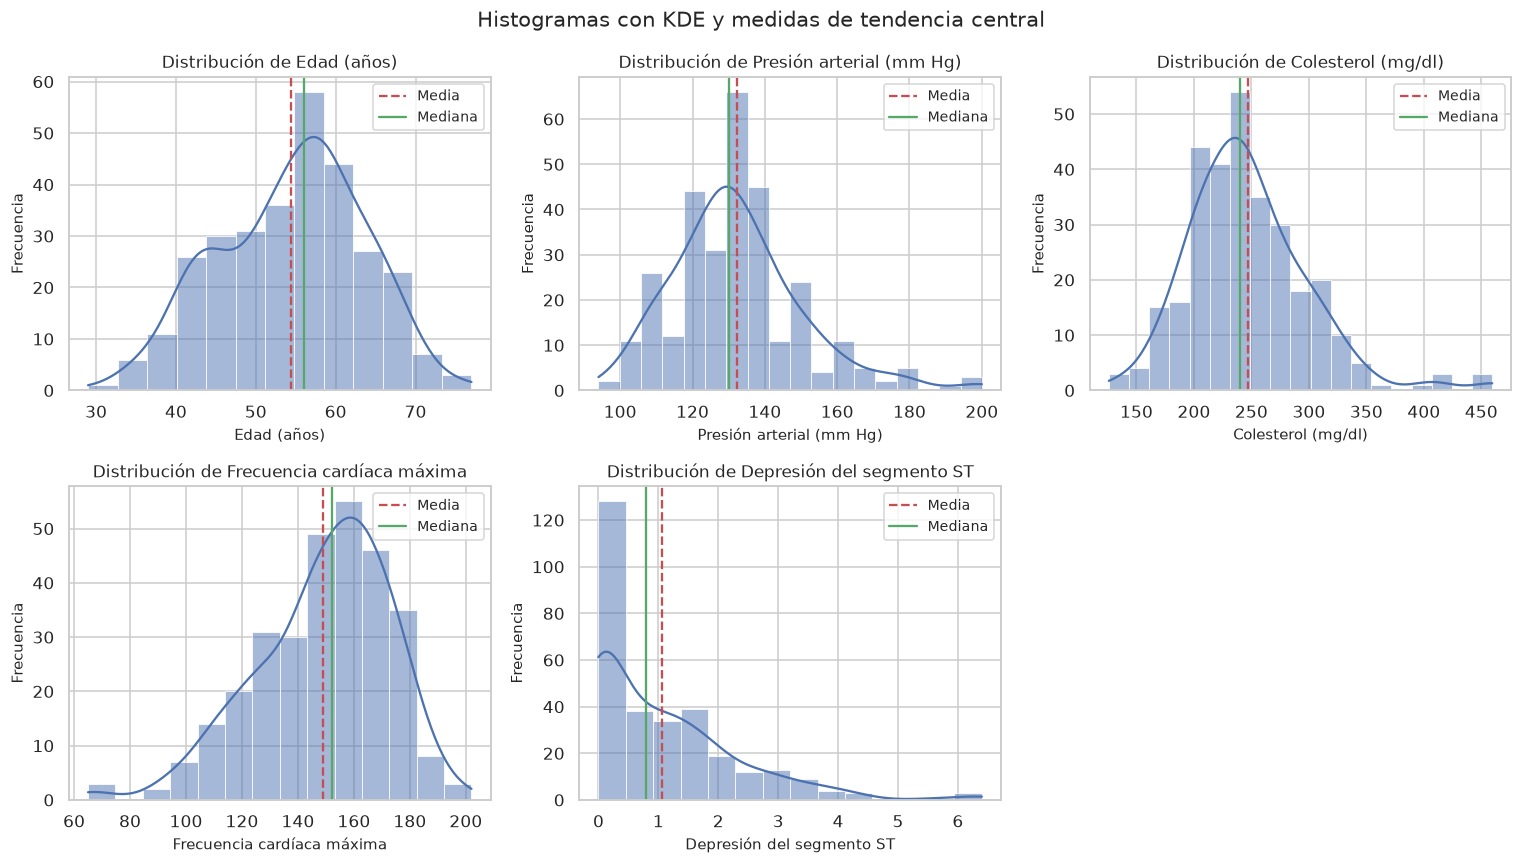

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for ax, col in zip(axes, COLS_NUM):
    sns.histplot(df_limpio[col], kde=True, ax=ax, color='#4C72B0', edgecolor='white', linewidth=0.5)
    ax.axvline(df_limpio[col].mean(), color='#C44E52', linestyle='--', linewidth=1.5, label='Media')
    ax.axvline(df_limpio[col].median(), color='#55A868', linestyle='-', linewidth=1.5, label='Mediana')
    ax.set_title(f'Distribución de {ETIQUETAS_VARS[col]}')
    ax.set_xlabel(ETIQUETAS_VARS[col])
    ax.set_ylabel('Frecuencia')
    ax.legend()

axes[-1].axis('off')
fig.suptitle('Histogramas con KDE y medidas de tendencia central', fontsize=14)
fig.tight_layout()
plt.show()

Lo que veo confirma la tabla. `age` tiene forma de campana, con el grueso entre 40 y 65 y una cola suave a la izquierda. `trestbps` se concentra entre 120 y 140 y tiene una cola derecha hasta 200. `chol` tiene el pico entre 200 y 280 y una cola larga hasta 459,5; por eso la media está por encima de la mediana. `thalach` se concentra entre 140 y 170 y tiene cola a la izquierda hasta 65. `oldpeak` es el más asimétrico: una barra enorme en 0 y una cola que llega a 6,4; la media (1,07) está por encima de la mediana (0,8).

El KDE de `oldpeak` hay que mirarlo con cuidado porque hay muchos valores repetidos en 0 y el suavizado puede exagerar la forma. No lo usaría para afirmar que la distribución es exactamente así.

Ahora separo por clase las dos variables que más parecen discriminar: `thalach` y `oldpeak`. Quiero ver si las distribuciones se desplazan o si se solapan casi por completo.

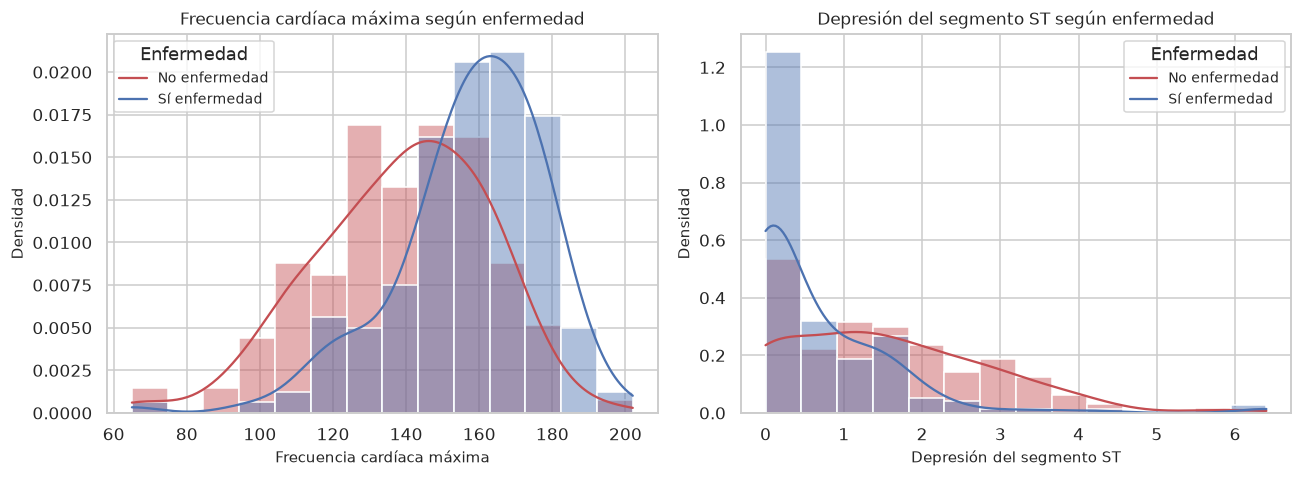

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, col in zip(axes, ['thalach', 'oldpeak']):
    sns.histplot(data=df_limpio, x=col, hue='enfermedad', hue_order=[0, 1], kde=True,
                 stat='density', common_norm=False, palette=PALETA_CLASES,
                 ax=ax, alpha=0.45, edgecolor='white')
    ax.set_title(f'{ETIQUETAS_VARS[col]} según enfermedad')
    ax.set_xlabel(ETIQUETAS_VARS[col])
    ax.set_ylabel('Densidad')
    ax.legend(title='Enfermedad', labels=ETIQUETAS_CLASES)

fig.tight_layout()
plt.show()

En `thalach` se ve un desplazamiento claro: el grupo con enfermedad tiene más masa entre 100 y 150, mientras que el grupo sin enfermedad se concentra entre 150 y 180. En `oldpeak` pasa lo contrario: el grupo con enfermedad tiene más masa por encima de 1, mientras que el grupo sin enfermedad se acumula cerca de 0. Aun así, hay mucho solapamiento; ninguna de las dos variables separa las clases por sí sola.

### 3.3 Boxplots por clase

Los boxplots resumen la mediana, los cuartiles y los outliers. Los hago por clase para comparar las distribuciones y ver si las diferencias que intuía en los histogramas se mantienen. El rombo blanco es la media.

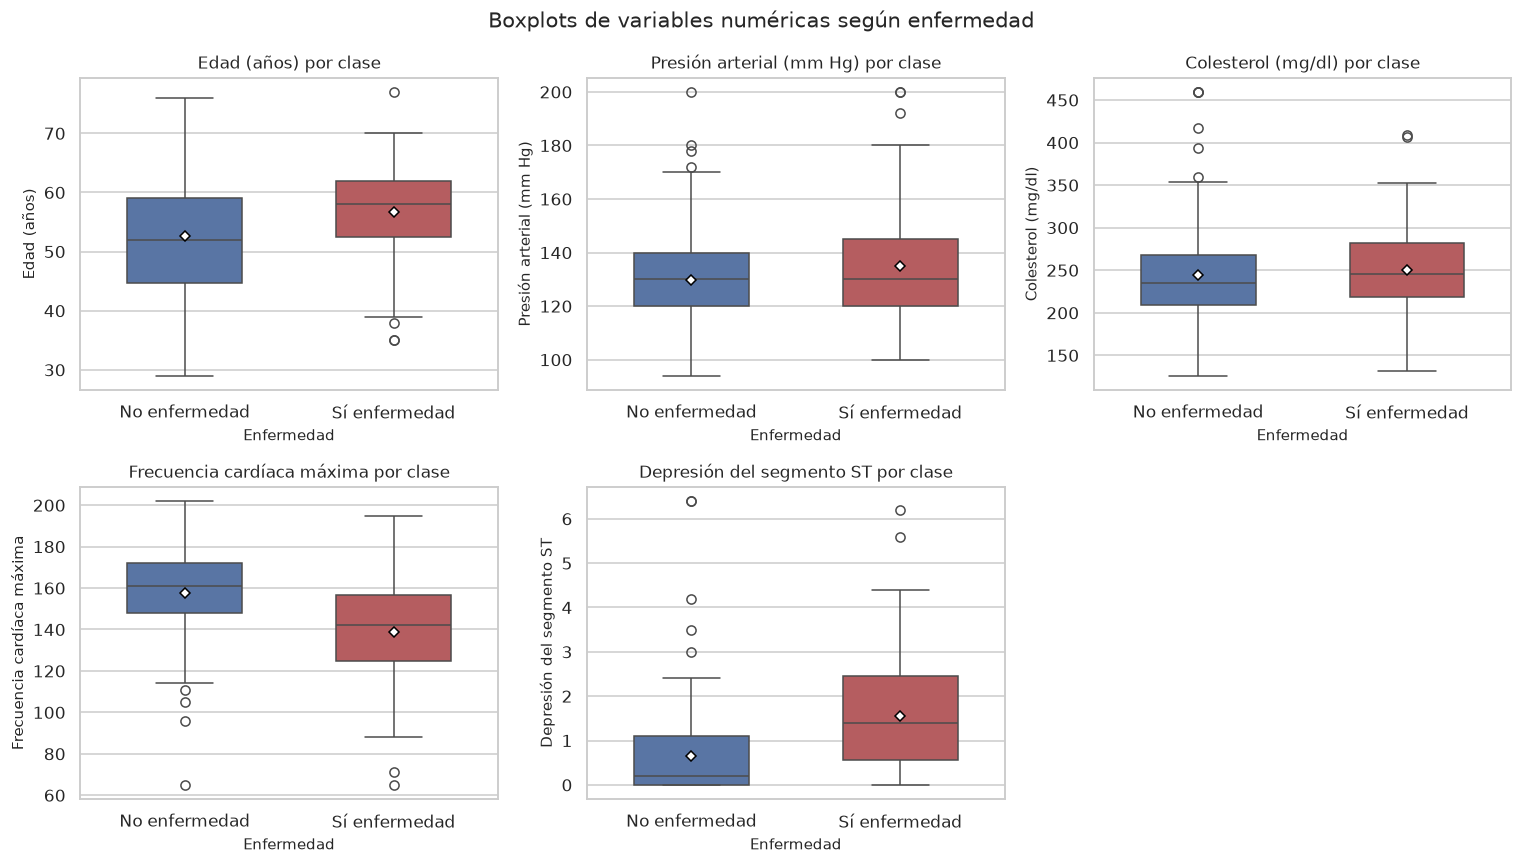

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes_flat = axes.ravel()

for ax, col in zip(axes_flat, COLS_NUM):
    sns.boxplot(data=df_limpio, x='enfermedad', y=col, hue='enfermedad',
                order=[0, 1], hue_order=[0, 1], palette=PALETA_CLASES,
                ax=ax, width=0.55, legend=False, showmeans=True,
                meanprops={'marker': 'D', 'markerfacecolor': 'white',
                           'markeredgecolor': 'black', 'markersize': 5})
    ax.set_title(f'{ETIQUETAS_VARS[col]} por clase')
    ax.set_xlabel('Enfermedad')
    ax.set_ylabel(ETIQUETAS_VARS[col])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(ETIQUETAS_CLASES)

axes_flat[-1].axis('off')
fig.suptitle('Boxplots de variables numéricas según enfermedad', fontsize=14)
fig.tight_layout()
plt.show()

La diferencia más clara está en `thalach`: mediana 161 en el grupo sin enfermedad frente a 142 en el grupo con enfermedad. Le sigue `oldpeak`: 0,2 frente a 1,4. `age` también sube (52 frente a 58), pero con mucho solapamiento. `chol` sube un poco (235,5 frente a 246) y `trestbps` tiene la misma mediana (130) aunque la media del grupo con enfermedad es más alta (135,13 frente a 129,81). Esto último me hace pensar que hay algunos valores altos en el grupo con enfermedad, pero no un desplazamiento general.

En `thalach` queda un outlier bajo de 65 en el grupo con enfermedad. Lo mantuve porque es clínicamente posible; el boxplot lo marca, pero no lo voy a borrar. Los outliers de `chol` y `trestbps` son valores altos que también podrían ser reales. La conclusión es que hay señal, pero no separación perfecta.

### 3.4 Countplots de categóricas

Miro las frecuencias de las categóricas separadas por clase. Quiero ver qué categorías concentran más enfermedad y cuáles tienen tan pocos casos que no merece la pena interpretarlas. Los números encima de las barras son recuentos, no porcentajes; los porcentajes los calculo en el apartado de agrupaciones.

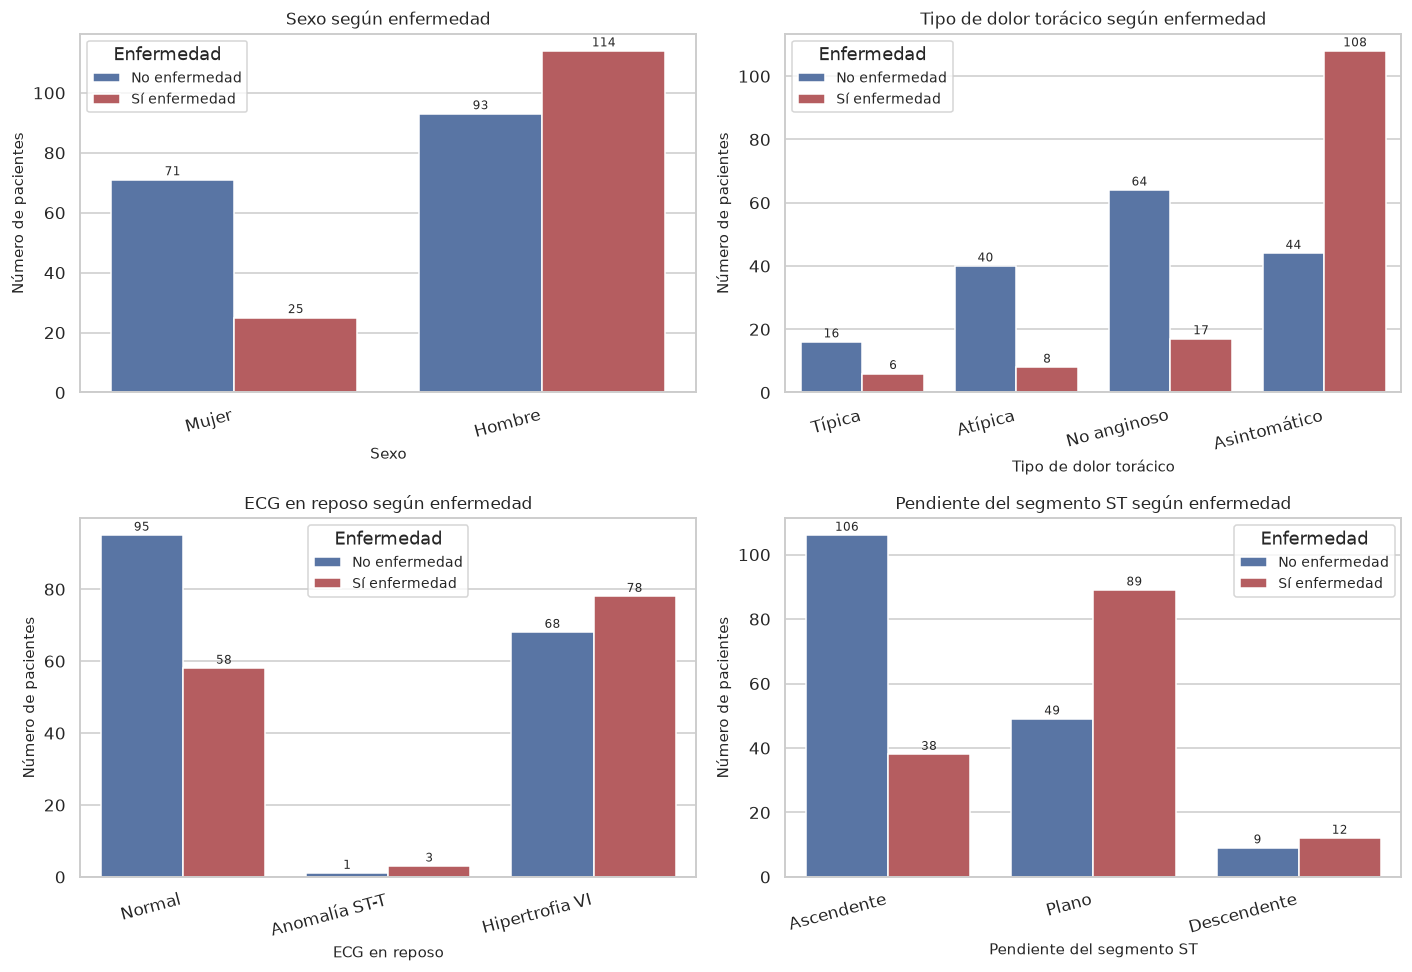

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.ravel(), ['sex', 'cp', 'restecg', 'slope']):
    sns.countplot(data=df_limpio, x=col, hue='enfermedad', hue_order=[0, 1],
                  palette=PALETA_CLASES, ax=ax)
    ax.set_title(f'{ETIQUETAS_CAT[col]} según enfermedad')
    ax.set_xlabel(ETIQUETAS_CAT[col])
    ax.set_ylabel('Número de pacientes')
    ax.set_xticks(range(len(TICKS_CAT[col])))
    ax.set_xticklabels(TICKS_CAT[col], rotation=15, ha='right')
    ax.legend(title='Enfermedad', labels=ETIQUETAS_CLASES)
    for contenedor in ax.containers:
        ax.bar_label(contenedor, fontsize=8, padding=1)

fig.tight_layout()
plt.show()

En `sex` se ve que la mayoría de los hombres del dataset tienen enfermedad (114 de 207), mientras que en las mujeres pasa lo contrario (25 de 96). En `cp`, la categoría asintomática es la que más enfermedad concentra (108 de 152), y la atípica la que menos (8 de 48). En `restecg`, la categoría de anomalía ST-T solo tiene 4 casos, así que su barra no es fiable aunque el porcentaje parezca alto. En `slope`, el patrón plano concentra más enfermedad que el ascendente.

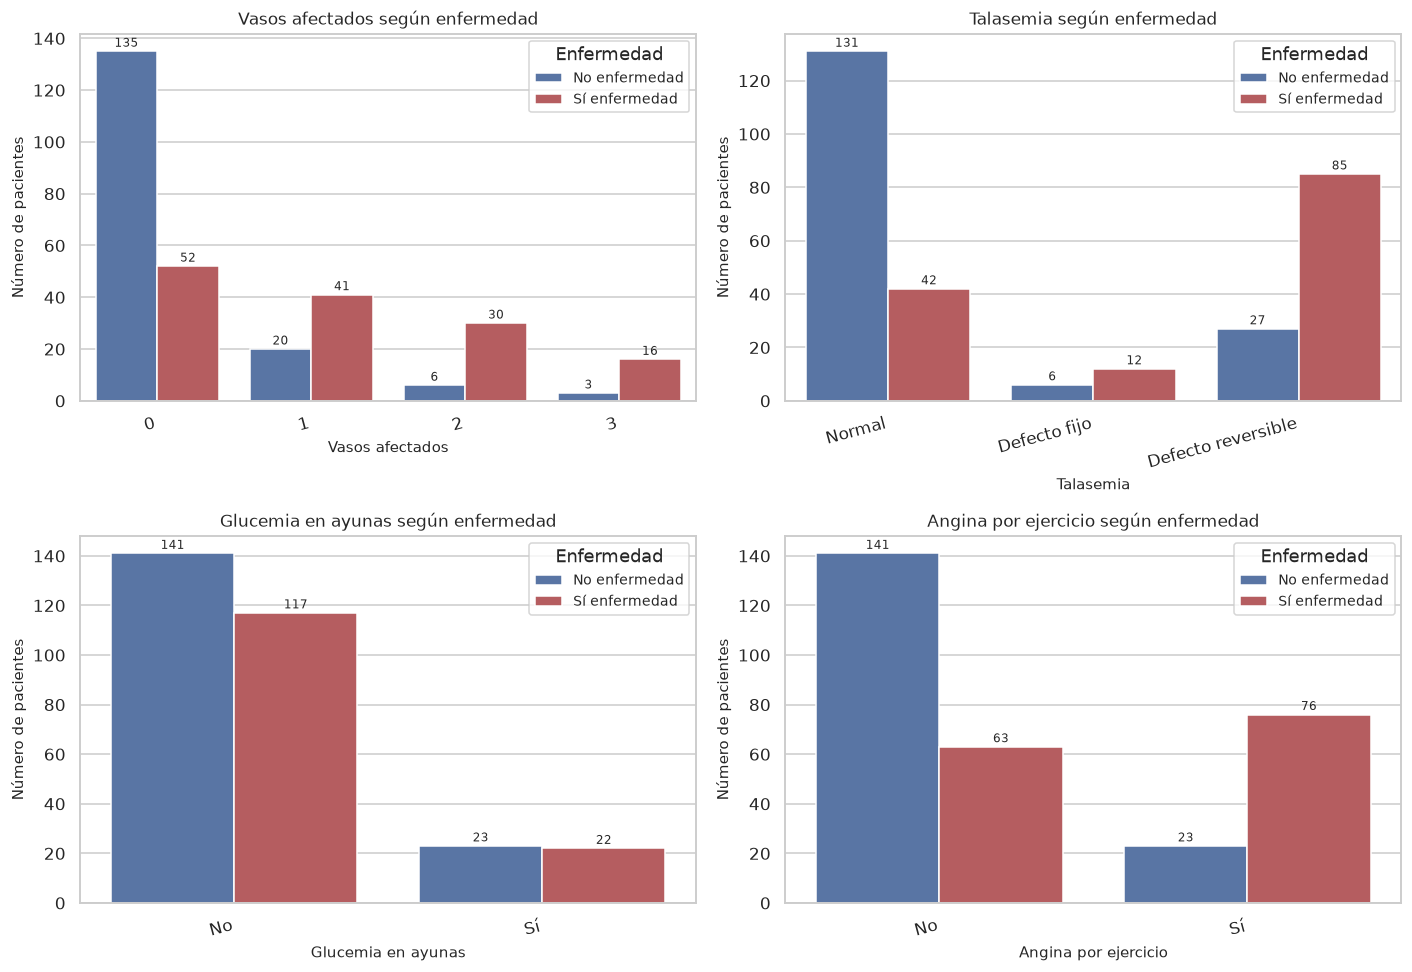

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.ravel(), ['ca', 'thal', 'fbs', 'exang']):
    sns.countplot(data=df_limpio, x=col, hue='enfermedad', hue_order=[0, 1],
                  palette=PALETA_CLASES, ax=ax)
    ax.set_title(f'{ETIQUETAS_CAT[col]} según enfermedad')
    ax.set_xlabel(ETIQUETAS_CAT[col])
    ax.set_ylabel('Número de pacientes')
    ax.set_xticks(range(len(TICKS_CAT[col])))
    ax.set_xticklabels(TICKS_CAT[col], rotation=15, ha='right')
    ax.legend(title='Enfermedad', labels=ETIQUETAS_CLASES)
    for contenedor in ax.containers:
        ax.bar_label(contenedor, fontsize=8, padding=1)

fig.tight_layout()
plt.show()

`ca` y `thal` son las que muestran patrones más ordenados. En `ca`, a medida que sube el número de vasos afectados, la proporción de enfermedad crece: de 52 de 187 con 0 vasos a 16 de 19 con 3. En `thal`, el defecto reversible (85 de 112) y el fijo (12 de 18) concentran mucha más enfermedad que el normal (42 de 173). En `fbs` las barras son casi iguales, y en `exang` se ve una diferencia grande: 76 de 99 con angina por ejercicio frente a 63 de 204 sin ella.

Me sorprende `cp=4`: no es la categoría que uno esperaría de mayor riesgo si solo mirase el nombre, pero en esta muestra es la que más enfermedad tiene. Puede ser un sesgo de derivación: los asintomáticos que llegan a angiografía probablemente llegan por otro motivo y con más sospecha.

### 3.5 Scatterplots

Los scatterplots permiten ver relaciones entre pares de variables y si las clases se separan en alguna combinación. Elijo tres pares: edad frente a frecuencia cardíaca, `oldpeak` frente a frecuencia cardíaca y colesterol frente a presión. El color indica la clase.

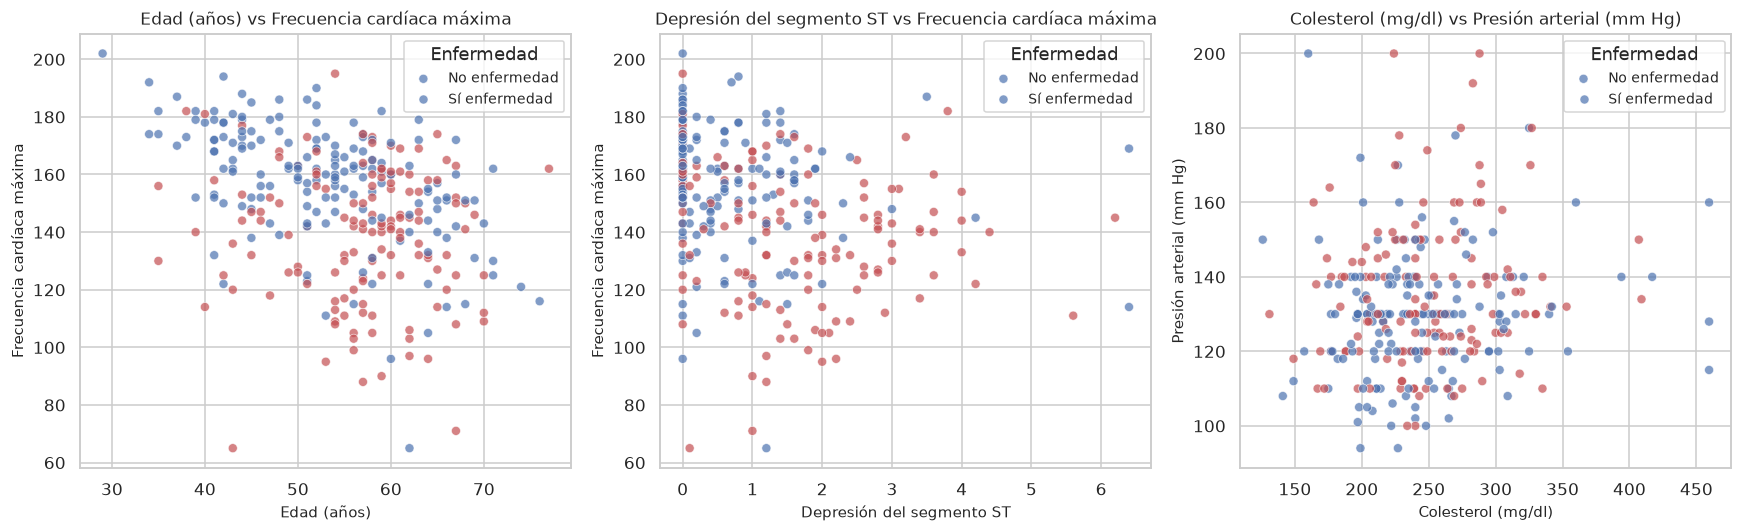

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
pares = [('age', 'thalach'), ('oldpeak', 'thalach'), ('chol', 'trestbps')]

for ax, (x, y) in zip(axes, pares):
    sns.scatterplot(data=df_limpio, x=x, y=y, hue='enfermedad', hue_order=[0, 1],
                    palette=PALETA_CLASES, alpha=0.7, s=35, ax=ax)
    ax.set_title(f'{ETIQUETAS_VARS[x]} vs {ETIQUETAS_VARS[y]}')
    ax.set_xlabel(ETIQUETAS_VARS[x])
    ax.set_ylabel(ETIQUETAS_VARS[y])
    ax.legend(title='Enfermedad', labels=ETIQUETAS_CLASES)

fig.tight_layout()
plt.show()

En el primer gráfico se ve que, a igualdad de edad, el grupo con enfermedad tiende a tener una frecuencia cardíaca máxima más baja. También hay una relación negativa entre edad y `thalach`: los mayores alcanzan menos frecuencia máxima. En el segundo, el grupo con enfermedad se concentra en `oldpeak` alto y `thalach` bajo, pero hay muchos puntos mezclados en el centro. En el tercero, colesterol y presión no muestran una separación clara; las dos clases se solapan casi por completo.

Esto no demuestra causalidad. Que la enfermedad se asocie con `oldpeak` alto no significa que `oldpeak` la cause; puede ser una consecuencia de la isquemia. Y las correlaciones pueden estar influidas por la edad, el sexo o el tipo de derivación.

### 3.6 Pairplot

El pairplot es una forma rápida de ver todas las relaciones entre las cinco numéricas a la vez. Uso la diagonal para las densidades por clase y la parte inferior para los dispersogramas. Con 303 puntos se lee bien, aunque no es un gráfico para sacar conclusiones finas.

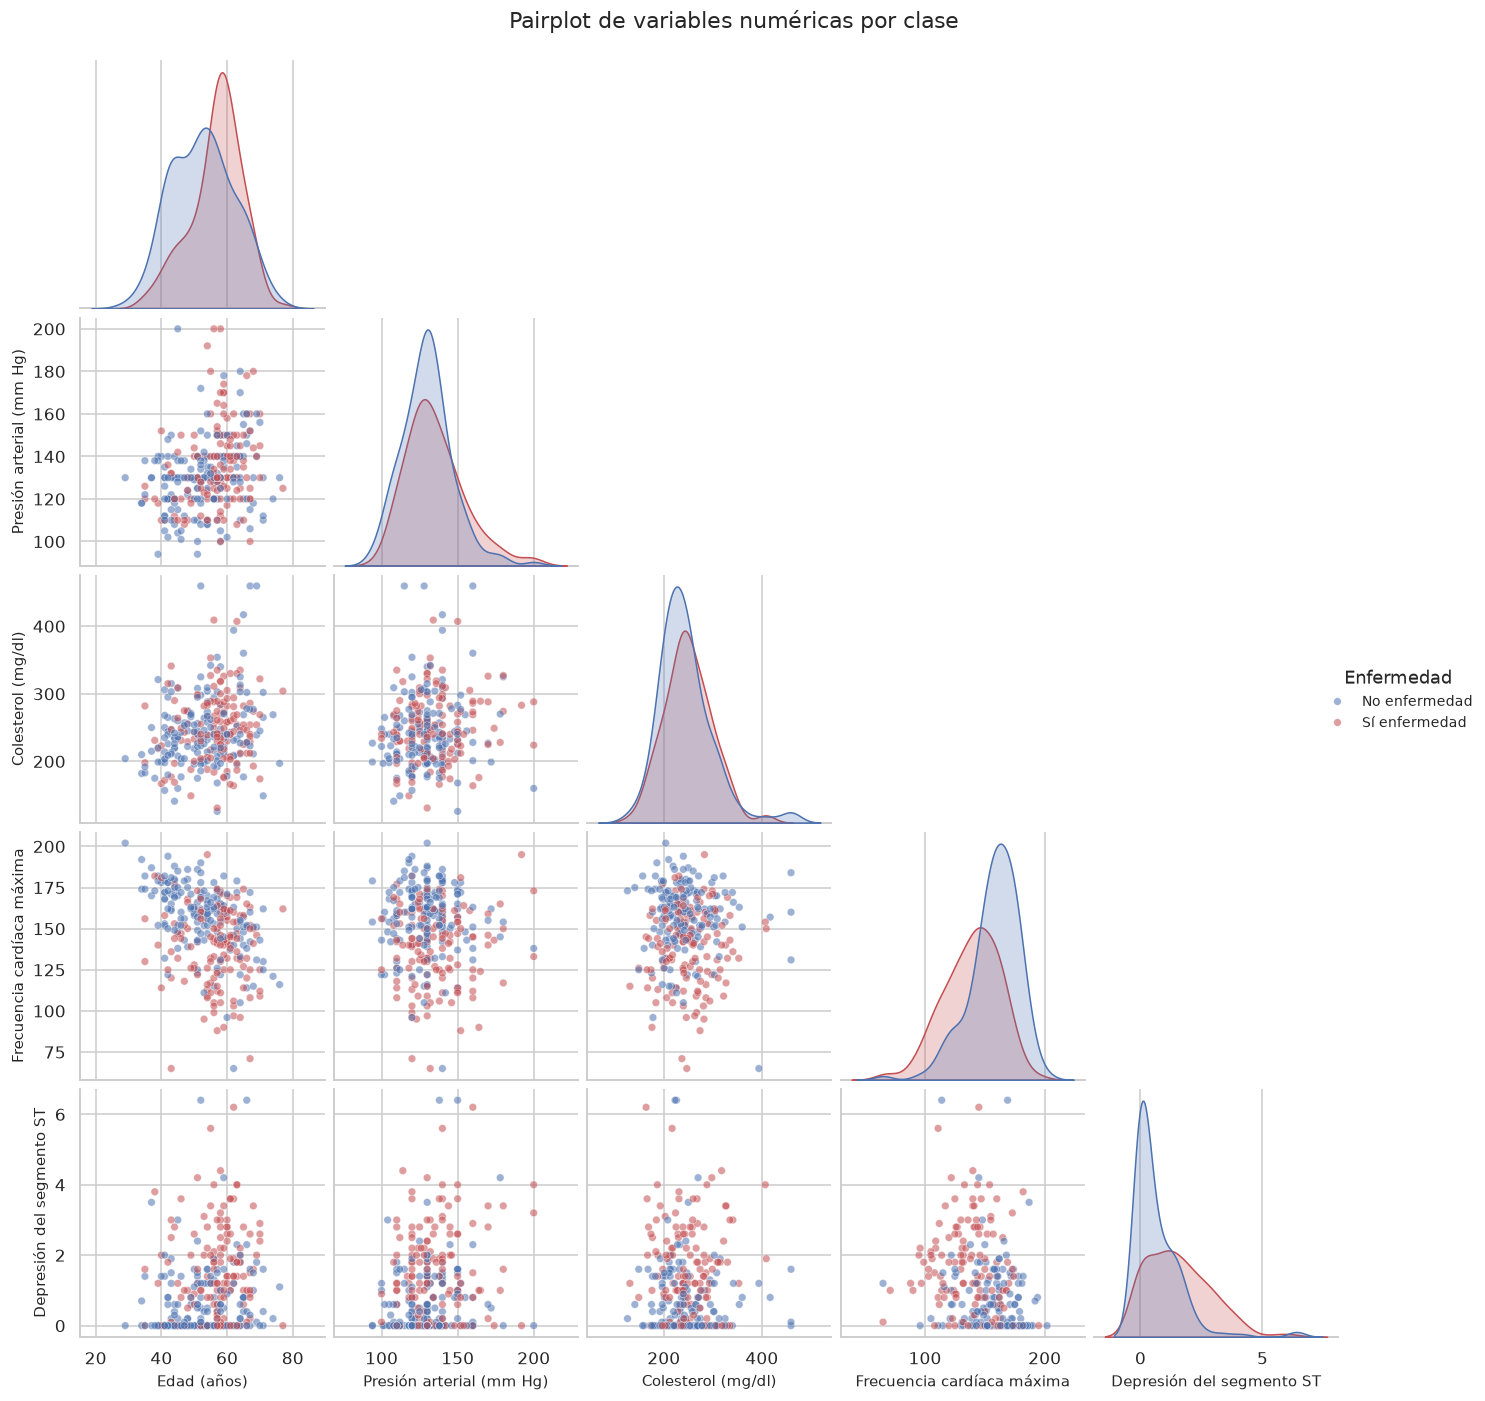

In [30]:
g = sns.pairplot(df_limpio, vars=COLS_NUM, hue='enfermedad', hue_order=[0, 1],
                 palette=PALETA_CLASES, corner=True, diag_kind='kde',
                 plot_kws={'alpha': 0.55, 's': 25})
g.fig.suptitle('Pairplot de variables numéricas por clase', y=1.02)

if g._legend is not None:
    g._legend.set_title('Enfermedad')
    for texto, etiqueta in zip(g._legend.texts, ETIQUETAS_CLASES):
        texto.set_text(etiqueta)

for ax in g.axes.flat:
    if ax is not None:
        ax.set_xlabel(ETIQUETAS_VARS.get(ax.get_xlabel(), ax.get_xlabel()))
        ax.set_ylabel(ETIQUETAS_VARS.get(ax.get_ylabel(), ax.get_ylabel()))

plt.show()

La diagonal confirma lo de los histogramas: `thalach` y `oldpeak` son las que más cambian entre clases, y `chol` y `trestbps` se parecen mucho. En los dispersogramas no hay una combinación que separe limpiamente los colores; hay solapamiento en todas. Eso no es raro en datos clínicos y es una razón para no confiar en una sola variable.

El pairplot no muestra causalidad ni tiene en cuenta las categóricas. Es una herramienta exploratoria, no un modelo.

### 3.7 Heatmap de correlación

Calculo la matriz de correlación de Pearson con las variables codificadas y la target. Incluyo los códigos originales de `cp`, `restecg`, `slope`, `ca` y `thal` para que la matriz sea legible, pero hay que recordar que en las nominales la correlación lineal es solo orientativa. En el modelo final esas variables van one-hot.

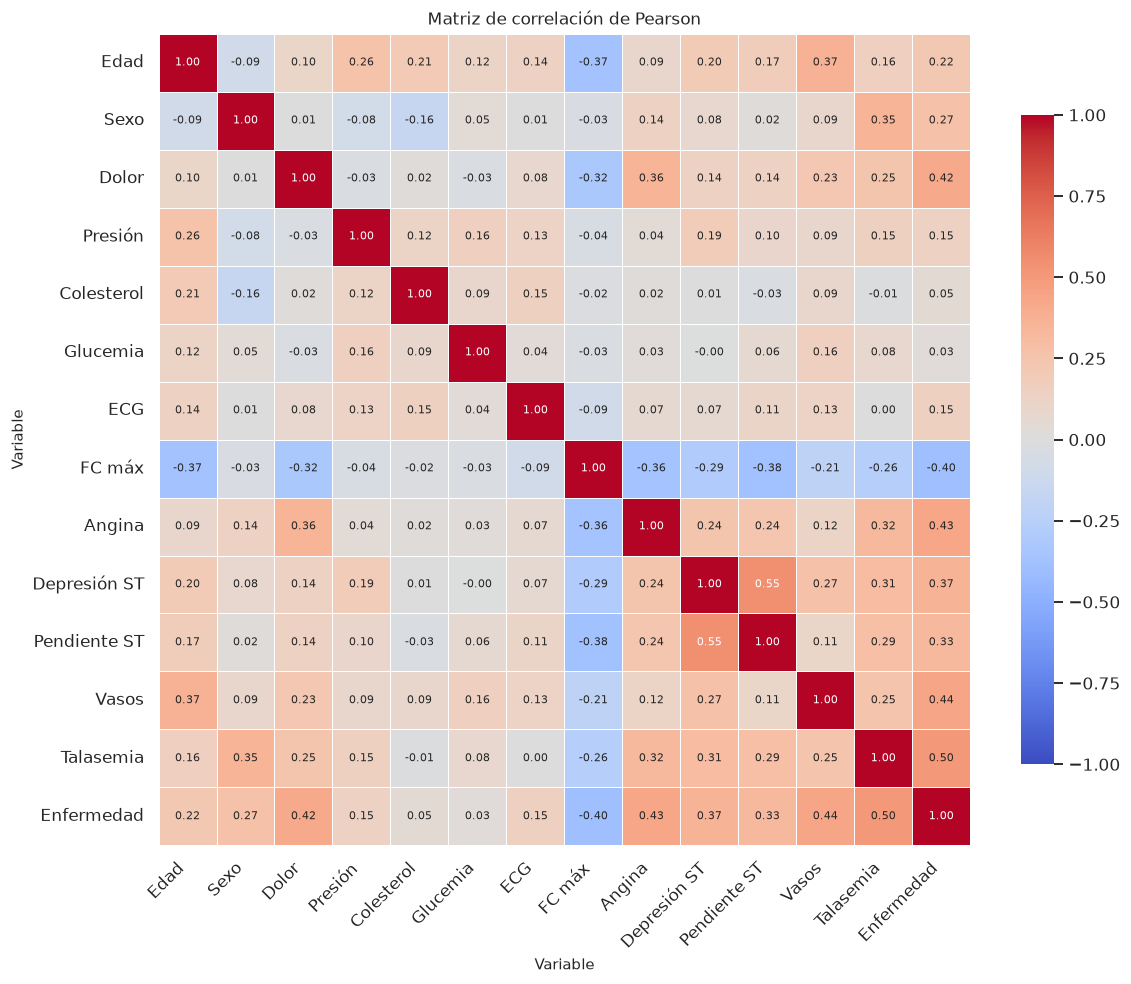

In [31]:
cols_corr = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
             'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'enfermedad']
corr = df_limpio[cols_corr].corr()

etiquetas_corr = ['Edad', 'Sexo', 'Dolor', 'Presión', 'Colesterol', 'Glucemia', 'ECG',
                  'FC máx', 'Angina', 'Depresión ST', 'Pendiente ST', 'Vasos', 'Talasemia', 'Enfermedad']

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8},
            annot_kws={'size': 7}, ax=ax)
ax.set_title('Matriz de correlación de Pearson')
ax.set_xlabel('Variable')
ax.set_ylabel('Variable')
ax.set_xticks(np.arange(len(etiquetas_corr)) + 0.5)
ax.set_xticklabels(etiquetas_corr, rotation=45, ha='right')
ax.set_yticks(np.arange(len(etiquetas_corr)) + 0.5)
ax.set_yticklabels(etiquetas_corr, rotation=0)
fig.tight_layout()
plt.show()

Las correlaciones con `enfermedad` ordenan bastante bien lo que he visto: `thal` 0,50, `ca` 0,44, `exang` 0,43, `cp` 0,42, `oldpeak` 0,37, `slope` 0,33, `sex` 0,27, `age` 0,22, `restecg` 0,15, `trestbps` 0,15, `chol` 0,05, `fbs` 0,03 y `thalach` -0,40. Las más débiles son `chol`, `fbs`, `trestbps` y `restecg`.

También hay dependencias entre predictoras que conviene vigilar: `oldpeak` y `slope` correlacionan 0,55; `thalach` y `slope` -0,38; `age` y `thalach` -0,37; `age` y `ca` 0,37; `cp` y `exang` 0,36; `sex` y `thal` 0,35. En una regresión logística no metería `oldpeak` y `slope` sin comprobar la multicolinealidad o sin regularizar. En un árbol importa menos, pero la importancia se reparte entre variables correlacionadas.

No confundir correlación con causalidad. `thal` y `ca` son variables diagnósticas, no factores de riesgo modificables; su asociación con la enfermedad es esperable porque miden lo mismo desde otro sitio.

### 3.8 Agrupaciones y tasas de enfermedad

Calculo tasas de enfermedad por sexo, tipo de dolor, rango de edad, número de vasos y talasemia. Muestro el número de casos y el porcentaje; no quiero interpretar un porcentaje sin saber cuántos pacientes hay detrás.

In [32]:
tablas = []

for col in ['sex', 'cp', 'ca', 'thal', 'restecg', 'slope']:
    tasa = (df_limpio.groupby(col)['enfermedad']
            .agg(['count', 'sum', 'mean'])
            .assign(pct=lambda d: (d['mean'] * 100).round(1))
            .reset_index()
            .rename(columns={col: 'categoria'}))
    tasa.insert(0, 'variable', col)
    tablas.append(tasa)

df_limpio['grupo_edad'] = pd.cut(df_limpio['age'], bins=[0, 39, 49, 59, 69, 120],
                                 labels=['<40', '40-49', '50-59', '60-69', '70+'])
tasa_edad = (df_limpio.groupby('grupo_edad', observed=True)['enfermedad']
             .agg(['count', 'sum', 'mean'])
             .assign(pct=lambda d: (d['mean'] * 100).round(1))
             .reset_index()
             .rename(columns={'grupo_edad': 'categoria'}))
tasa_edad.insert(0, 'variable', 'grupo_edad')
tablas.append(tasa_edad)

pd.concat(tablas, ignore_index=True)

,variable,categoria,count,sum,mean,pct
0,sex,0,96,25,0.260417,26.0
1,sex,1,207,114,0.550725,55.1
2,cp,1,22,6,0.272727,27.3
3,cp,2,48,8,0.166667,16.7
4,cp,3,81,17,0.209877,21.0
5,cp,4,152,108,0.710526,71.1
6,ca,0,187,52,0.278075,27.8
7,ca,1,61,41,0.672131,67.2
8,ca,2,36,30,0.833333,83.3
9,ca,3,19,16,0.842105,84.2


Las tasas más altas están en `thal=7` (75,9%, n=112), `ca=3` (84,2%, n=19), `exang=1` (76,8%, n=99), `cp=4` (71,1%, n=152) y `slope=2` (64,5%, n=138). Las más bajas están en `thal=3` (24,3%, n=173), `ca=0` (27,8%, n=187), `cp=2` (16,7%, n=48) y `slope=1` (26,4%, n=144). El sexo también marca: 26,0% en mujeres frente a 55,1% en hombres.

La edad sube hasta los 60-69 (60,0%, n=80) y luego baja a 40,0% en 70+ (n=10). Ese último grupo es demasiado pequeño para tomarlo en serio; probablemente es ruido. `restecg=1` tiene 75,0% con solo 4 casos, así que no lo usaría para concluir nada. `fbs` es la más plana: 45,3% con 0 y 48,9% con 1.

Ahora los dos gráficos que resumen las agrupaciones más claras: sexo y tipo de dolor; edad y número de vasos. Los porcentajes van anotados con el tamaño muestral para no perder el contexto.

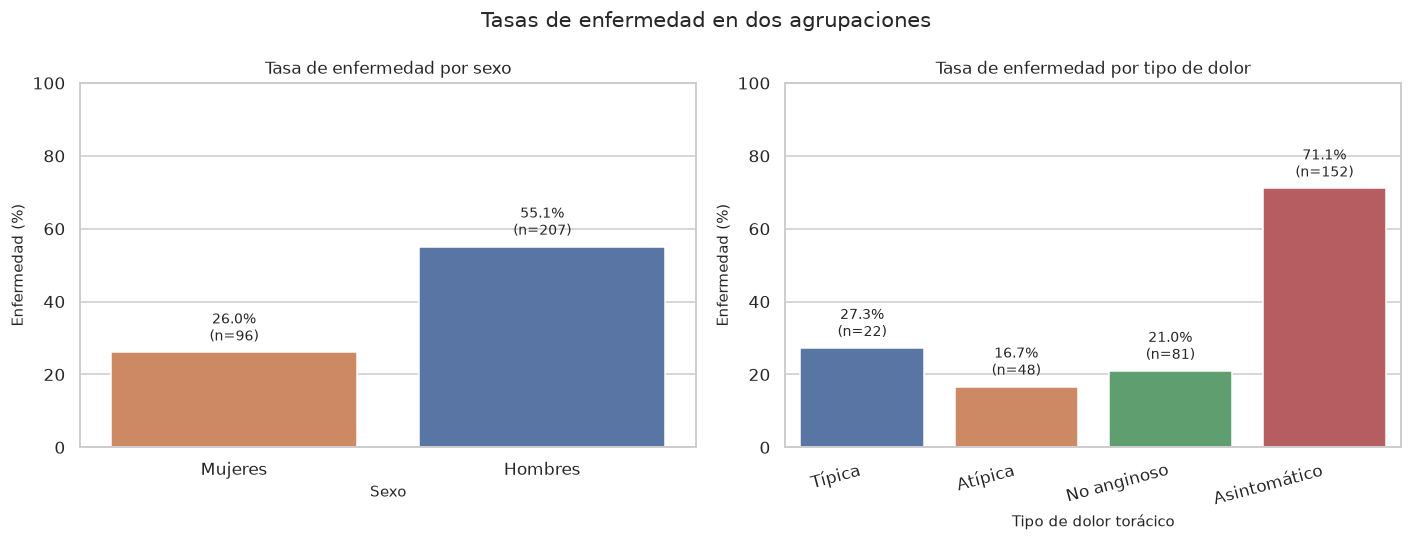

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

tasa_sexo = df_limpio.groupby('sex')['enfermedad'].agg(['count', 'mean']).reset_index()
tasa_sexo['pct'] = tasa_sexo['mean'] * 100
sns.barplot(data=tasa_sexo, x='sex', y='pct', hue='sex',
            palette=['#DD8452', '#4C72B0'], ax=axes[0], legend=False, errorbar=None)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Mujeres', 'Hombres'])
axes[0].set_title('Tasa de enfermedad por sexo')
axes[0].set_xlabel('Sexo')
axes[0].set_ylabel('Enfermedad (%)')
axes[0].set_ylim(0, 100)
for i, fila in tasa_sexo.iterrows():
    axes[0].text(i, fila['pct'] + 2, f"{fila['pct']:.1f}%\n(n={int(fila['count'])})",
                 ha='center', va='bottom', fontsize=9)

tasa_cp = df_limpio.groupby('cp')['enfermedad'].agg(['count', 'mean']).reset_index()
tasa_cp['pct'] = tasa_cp['mean'] * 100
sns.barplot(data=tasa_cp, x='cp', y='pct', hue='cp', palette='deep',
            ax=axes[1], legend=False, errorbar=None)
axes[1].set_xticks(range(len(tasa_cp)))
axes[1].set_xticklabels(TICKS_CAT['cp'], rotation=15, ha='right')
axes[1].set_title('Tasa de enfermedad por tipo de dolor')
axes[1].set_xlabel('Tipo de dolor torácico')
axes[1].set_ylabel('Enfermedad (%)')
axes[1].set_ylim(0, 100)
for i, fila in tasa_cp.iterrows():
    axes[1].text(i, fila['pct'] + 2, f"{fila['pct']:.1f}%\n(n={int(fila['count'])})",
                 ha='center', va='bottom', fontsize=9)

fig.suptitle('Tasas de enfermedad en dos agrupaciones', fontsize=14)
fig.tight_layout()
plt.show()

El gráfico de sexo muestra una diferencia de casi 30 puntos porcentuales: 26,0% en mujeres y 55,1% en hombres. No sé si esa diferencia es biológica, de derivación o de composición de la muestra; con estos datos no puedo separarlo. El de tipo de dolor es más llamativo: `cp=4` (asintomático) llega al 71,1%, mientras que `cp=2` (atípica) se queda en 16,7%. La categoría típica tiene 27,3% con solo 22 casos.

Me sorprende que la angina típica no sea la de mayor tasa. Puede ser porque en este dataset los pacientes asintomáticos llegan a angiografía por otros signos y ya tienen enfermedad avanzada. Es una hipótesis, no una conclusión.

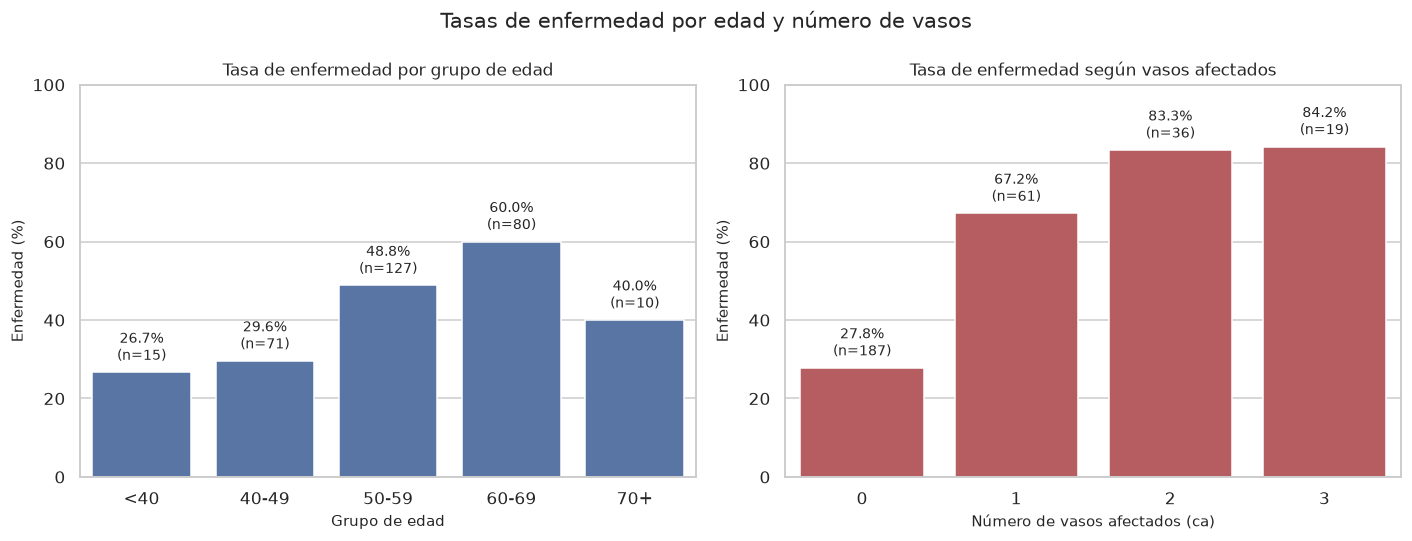

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

tasa_edad = (df_limpio.groupby('grupo_edad', observed=True)['enfermedad']
             .agg(['count', 'mean']).reset_index())
tasa_edad['pct'] = tasa_edad['mean'] * 100
sns.barplot(data=tasa_edad, x='grupo_edad', y='pct', color='#4C72B0',
            ax=axes[0], errorbar=None)
axes[0].set_title('Tasa de enfermedad por grupo de edad')
axes[0].set_xlabel('Grupo de edad')
axes[0].set_ylabel('Enfermedad (%)')
axes[0].set_ylim(0, 100)
for i, fila in tasa_edad.iterrows():
    axes[0].text(i, fila['pct'] + 2, f"{fila['pct']:.1f}%\n(n={int(fila['count'])})",
                 ha='center', va='bottom', fontsize=9)

tasa_ca = df_limpio.groupby('ca')['enfermedad'].agg(['count', 'mean']).reset_index()
tasa_ca['pct'] = tasa_ca['mean'] * 100
sns.barplot(data=tasa_ca, x='ca', y='pct', color='#C44E52', ax=axes[1], errorbar=None)
axes[1].set_xticks(range(len(tasa_ca)))
axes[1].set_xticklabels(TICKS_CAT['ca'])
axes[1].set_title('Tasa de enfermedad según vasos afectados')
axes[1].set_xlabel('Número de vasos afectados (ca)')
axes[1].set_ylabel('Enfermedad (%)')
axes[1].set_ylim(0, 100)
for i, fila in tasa_ca.iterrows():
    axes[1].text(i, fila['pct'] + 2, f"{fila['pct']:.1f}%\n(n={int(fila['count'])})",
                 ha='center', va='bottom', fontsize=9)

fig.suptitle('Tasas de enfermedad por edad y número de vasos', fontsize=14)
fig.tight_layout()
plt.show()

La edad muestra un aumento hasta los 60-69 (60,0%), pero el grupo 70+ tiene solo 10 pacientes y baja a 40,0%. No me fío de esa caída; con 10 casos, un par de pacientes cambia mucho el porcentaje. La relación con `ca` es más regular: 27,8% con 0 vasos, 67,2% con 1, 83,3% con 2 y 84,2% con 3. Es una de las señales más fuertes del dataset, aunque `ca` se mide después de la angiografía y no sería una variable disponible antes de la prueba en un escenario real. Eso es importante: si `ca` se obtiene en el mismo proceso diagnóstico, puede ser una variable con fuga temporal. No lo puedo resolver con este dataset; lo dejo anotado.

### 3.9 Limitaciones del análisis

- **Correlación no es causalidad.** Las asociaciones con `thal`, `ca` o `oldpeak` pueden reflejar el mismo proceso diagnóstico, no una relación causal.
- **Muestra pequeña y de un solo centro.** 303 pacientes de Cleveland, con datos de 1988. No representan a la población actual ni a otros hospitales.
- **Sesgo de derivación.** Los pacientes llegan a angiografía por criterios que no conozco. Eso puede explicar que `cp=4` tenga una tasa tan alta.
- **Categorías raras.** `restecg=1` tiene 4 casos y `cp=1` 22; sus porcentajes son inestables.
- **Variables codificadas.** `cp`, `restecg`, `slope`, `ca` y `thal` son códigos, no magnitudes. La correlación de Pearson con esos códigos es solo orientativa.
- **Imputación simple.** La mediana y la moda no usan información de otras variables y pueden sesgar las distribuciones. La auditoría muestra que la moda acierta poco en `cp`, `thal` y `ca`.
- **Target binarizada.** Pierdo la gravedad (`num=1` frente a `num=4`). Para un modelo clínico, quizá interese un problema ordinal o multiclase.
- **Datos autodeclarados o medidos con protocolos antiguos.** No puedo verificar la calidad del origen.

## 4. Conclusión

### 4.1 Hallazgos principales

El dataset tiene 303 pacientes y 13 predictores. La enfermedad está presente en 139 casos (45,9%), así que las clases están razonablemente equilibradas. Las señales más claras son `thal`, `ca`, `exang`, `cp`, `oldpeak` y `thalach`: correlaciones de 0,50, 0,44, 0,43, 0,42, 0,37 y -0,40. Por grupos, los hombres tienen una tasa de 55,1% frente al 26,0% de las mujeres; `cp=4` llega al 71,1%, mientras que `cp=2` se queda en 16,7%; con 3 vasos afectados la tasa es 84,2% y con 0 vasos 27,8%; `thal=7` es 75,9% frente a `thal=3` 24,3%.

La edad sube la tasa hasta los 60-69 (60,0%), pero el grupo 70+ tiene solo 10 pacientes y baja a 40,0%, así que no me fío de ese último punto. `chol`, `trestbps`, `fbs` y `restecg` muestran asociaciones débiles (0,05, 0,15, 0,03 y 0,15). No quiere decir que no sean importantes médicamente; en esta muestra no separan bien.

### 4.2 Variables que usaría y variables que vigilaría

Como buenas predictoras me quedo con `thal`, `ca`, `exang`, `cp`, `oldpeak`, `thalach`, `slope`, `sex` y, en menor medida, `age`. Descartaría o vigilaría `fbs` (correlación 0,03 y tasas 45,3% vs 48,9%), `chol` (0,05) y `trestbps` (0,15). `restecg` tiene una categoría con 4 casos; la mantendría con cuidado o la agruparía.

Hay multicolinealidad que no quiero ignorar: `oldpeak` y `slope` correlacionan 0,55; `thalach` y `slope` -0,38; `age` y `thalach` -0,37; `age` y `ca` 0,37; `cp` y `exang` 0,36. En una regresión logística no metería `oldpeak` y `slope` sin comprobar VIF o sin regularizar. En un árbol importa menos, pero la importancia se reparte entre variables correlacionadas y la interpretación se vuelve menos clara.

La variable objetivo es `enfermedad` (1 si `num` > 0). No usaría `num` como predictor después de crear la target.

### 4.3 Por qué es clasificación y qué probaría después

Es un problema de clasificación porque `enfermedad` es discreta (0/1). Podría haber hecho regresión ordinal con `num` 0-4, pero la clase 4 tiene 13 casos y la pregunta clínica es presencia/ausencia. Probaría una **regresión logística** como base interpretable, un **árbol de decisión** con profundidad controlada, **k-NN** con escalado y quizá **random forest** o gradient boosting. La regresión logística me daría coeficientes y probabilidades; el árbol, reglas; k-NN es sensible a la escala y a las variables irrelevantes, así que habría que seleccionar y escalar bien.

Dado el balance 54/46, la accuracy es útil, pero en cribado clínico me importa más el **recall** (no dejar pasar enfermos) y miraría también precisión, F1, ROC-AUC, PR-AUC y la matriz de confusión. Si bajo el umbral para ganar recall, acepto más falsos positivos; hay que decidirlo con el coste clínico. Usaría validación cruzada estratificada y un test reservado.

### 4.4 Precauciones: data leakage y evaluación

Separaría train/test antes de imputar, escalar o codificar. Si calculo la mediana o la moda con todo el dataset, el test se filtra al train y las métricas salen optimistas. Lo mismo con el escalado y con cualquier selección de variables. En la siguiente práctica lo haría con un `Pipeline` y un `ColumnTransformer`: el pipeline se ajusta solo con train y transforma test con lo aprendido.

También fijaría la semilla, guardaría la partición y revisaría que las categorías raras aparezcan en ambos conjuntos. Si una categoría solo está en test, el one-hot tendría que ignorarla o usar `handle_unknown='ignore'`. No usaría `num` como predictor después de crear `enfermedad`, y no elegiría variables mirando el test.

### 4.5 Autocrítica

El dataset es pequeño (303), de un solo centro (Cleveland) y de 1988. Los pacientes no son una muestra aleatoria de la población actual; hay sesgo de derivación, sobre todo en `cp=4` asintomático, que quizá llega a angiografía por otros motivos. Los códigos son antiguos y algunas categorías tienen muy pocos casos. La binarización pierde gravedad: no es lo mismo `num=1` que `num=4`. La imputación por moda puede inventar categorías y la mediana puede suavizar extremos reales. Los outliers que he mantenido (por ejemplo, `thalach=65`) son plausibles, pero no puedo asegurar que no sean errores. Y las correlaciones son asociaciones, no causas.

Tampoco puedo prometer que la limpieza sea perfecta. He comprobado que no quedan nulos, duplicados ni valores imposibles, pero eso no garantiza que no haya errores semánticos: un `cp` mal codificado pero dentro del dominio sería invisible para mis reglas. La auditoría de la imputación muestra que la moda acierta poco en `cp`, `thal` y `ca`; una imputación más fina tendría que usar las otras variables y validarse con cuidado.

### 4.6 Cierre

Me quedo con que la limpieza funciona y que hay señal suficiente para clasificar, pero no para prometer un modelo clínico. La siguiente práctica debería centrarse en partir bien los datos, probar modelos simples y mirar recall y matriz de confusión, no solo accuracy. Si el modelo final va a usarse en un contexto real, habría que validarlo externamente y revisar el sesgo por sexo, edad y centro.

## Anexo: cómo empaquetar la entrega

Para entregar, creo una carpeta con el notebook y el CSV:

```text
APAU_U1U2_Act1_IsmaelHernandez/
├── APAU_U1U2_Act1_IsmaelHernandez.ipynb
└── heart_disease_cleveland.csv
```

Y la comprimo como `APAU_U1U2_Act1_IsmaelHernandez.zip`. El notebook debe abrirse desde esa carpeta para que la ruta relativa del CSV funcione. Antes de entregar, ejecuto *Restart & Run All* y compruebo que no hay errores ni celdas vacías. El CSV es el archivo original de UCI con cabecera; el notebook genera el dataset limpio y codificado, pero no necesita guardarlo para funcionar.